# 04 Auto-GlaKG（ACRIMA 版）：用图像预测的生物标志物实例化知识图谱

**目的**：在现有 ACRIMA 数据（BIBM 版使用的 parquet）上，把推理时的标注生物标志物换成**从图像预测的生物标志物**，比较 Oracle-KG 与 Auto-KG，同时修正 BIBM 代码中的评估问题。

**需要清楚的局限**：ACRIMA 的生物标志物是 AI 生成的，与诊断标签高度相关（Cell 4 会直接展示）。因此生物标志物预测头学到的信号与诊断很接近，Auto-KG 的结果主要反映"图像模型复现这些标注的能力"。这是一个过渡实验，正式结论仍需 G1020 这类有独立测量的数据。

**与 BIBM 代码相比的修正**：
1. 只保留临床先验规则，去掉在全部数据上统计得到的 data_derived 规则与强度
2. 带符号链分数（正常证据减分），固定 sigmoid 映射，不再用全数据 min-max
3. 嵌套交叉验证：模型只在内部训练集上训练，融合权重 α 只在内部验证集上选
4. 图像基线改为微调的 ResNet50，输入直接缩放到 224，不再中心裁剪
5. 感知哈希去重分组，防止近似图像跨折
6. 确定性节点 ID

**运行**：`MOCK = True` 用合成数据自检（跳过 Cell 9）；确认无误后 `MOCK = False` 正式运行。支持 CUDA、Apple MPS 与 CPU。

**评估内容**：主结果（各折均值 ± 标准差，以及按组自助法 95% 置信区间）、统计检验（DeLong、McNemar，Holm 校正）、消融（逐条去规则、生物标志物子集、权重方案、温度与尺度敏感性、融合权重曲线）、解释一致性、亚组分析、图像扰动鲁棒性、模型复杂度、误判分析，以及 18 张论文用图。所有表格同时导出 CSV 与 LaTeX。

In [43]:
# ═══════════════════════════════════════════════════════════
# Cell 1: 导入包
# ═══════════════════════════════════════════════════════════
import io
import json
import random
import shutil
import warnings
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import pearsonr
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)

In [44]:
# ═══════════════════════════════════════════════════════════
# Cell 2: 全局配置
# ═══════════════════════════════════════════════════════════
MOCK = False   # True: 合成数据 + 模拟模型，只检查流程

@dataclass
class Config:
    # ---------- 数据 ----------
    data_dir: str = "data"                            # 两个 parquet 放在 notebook 同级的 data/ 文件夹
    train_file: str = "train-00000-of-00001.parquet"
    test_file: str = "test-00000-of-00001.parquet"
    load_size: int = 256                              # 预加载时统一缩放的尺寸
    phash_threshold: int = 4                          # 近重复检测的汉明距离阈值
    out_dir: str = "outputs_acrima"
    seed: int = 42

    # ---------- 实验协议 ----------
    n_folds: int = 5
    inner_val_frac: float = 0.2                       # 训练折中留出的内部验证比例，只用于选 alpha

    # ---------- 模型 ----------
    img_size: int = 224
    cls_epochs: int = 15                              # 诊断分类器
    bm_epochs: int = 15                               # 生物标志物预测网络
    lr: float = 1e-4
    batch_size: int = 32
    num_workers: int = 0                              # macOS / Windows 的 Jupyter 中保持 0
    device: str = "auto"                              # auto: cuda > mps > cpu

    # ---------- 规则与 KG ----------
    strength_weight: dict = field(default_factory=lambda: {"strong": 3.0, "moderate": 2.0, "weak": 1.0})
    soft_T_cdr: float = 0.03                          # CDR 阈值的 sigmoid 松弛温度
    score_scale: float = 1.5                          # p_KG = sigmoid(带符号链分数 / score_scale)
    alphas: Tuple[float, ...] = tuple(round(0.1 * i, 1) for i in range(11))   # 融合时 KG 的权重候选

    # ---------- 扩展评估 ----------
    n_boot: int = 1000                                # 自助法重采样次数（按组重采样）
    robustness: dict = field(default_factory=lambda: {  # 测试时图像扰动及其强度
        "gaussian_blur": [1.0, 2.0, 3.0], "gaussian_noise": [5.0, 10.0, 20.0],
        "brightness": [0.6, 0.8, 1.2, 1.4], "contrast": [0.6, 0.8, 1.2, 1.4], "jpeg": [50, 30, 10]})
    temp_sweep: Tuple[float, ...] = (0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12)   # CDR 软阈值温度
    scale_sweep: Tuple[float, ...] = (0.5, 1.0, 1.5, 2.0, 3.0, 5.0)               # 链分数尺度
    n_gradcam: int = 6                                # Grad-CAM 展示的图像数

CFG = Config()
if MOCK:
    CFG.data_dir, CFG.out_dir, CFG.n_folds = "smoke_acrima", "smoke_out_acrima", 3

random.seed(CFG.seed)
np.random.seed(CFG.seed)
OUT = Path(CFG.out_dir)
OUT.mkdir(parents=True, exist_ok=True)
print(json.dumps(asdict(CFG), indent=2, ensure_ascii=False))

{
  "data_dir": "data",
  "train_file": "train-00000-of-00001.parquet",
  "test_file": "test-00000-of-00001.parquet",
  "load_size": 256,
  "phash_threshold": 4,
  "out_dir": "outputs_acrima",
  "seed": 42,
  "n_folds": 5,
  "inner_val_frac": 0.2,
  "img_size": 224,
  "cls_epochs": 15,
  "bm_epochs": 15,
  "lr": 0.0001,
  "batch_size": 32,
  "num_workers": 0,
  "device": "auto",
  "strength_weight": {
    "strong": 3.0,
    "moderate": 2.0,
    "weak": 1.0
  },
  "soft_T_cdr": 0.03,
  "score_scale": 1.5,
  "alphas": [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
  ],
  "n_boot": 1000,
  "robustness": {
    "gaussian_blur": [
      1.0,
      2.0,
      3.0
    ],
    "gaussian_noise": [
      5.0,
      10.0,
      20.0
    ],
    "brightness": [
      0.6,
      0.8,
      1.2,
      1.4
    ],
    "contrast": [
      0.6,
      0.8,
      1.2,
      1.4
    ],
    "jpeg": [
      50,
      30,
      10
    ]
  },
  "temp_sweep": [


In [45]:
# ═══════════════════════════════════════════════════════════
# Cell 3: 读取 parquet，解码图像，解析生物标志物
# ═══════════════════════════════════════════════════════════
# 二值生物标志物统一表示为"异常 = 1"：ISNT 用 isnt_violated = not isnt_rule_followed
BIN_COLS = ["isnt_violated", "rim_thinning", "notching", "bayoneting", "rim_pallor", "laminar_dot_sign"]
BM_COLS = ["cdr"] + BIN_COLS

def _to_bool(v):
    if isinstance(v, (bool, np.bool_)):
        return float(v)
    if isinstance(v, str) and v.strip().lower() in ("true", "false"):
        return float(v.strip().lower() == "true")
    return np.nan

def _to_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan

def parse_description(raw):
    try:
        ff = json.loads(raw).get("fundus_features", {})
    except (TypeError, json.JSONDecodeError):
        ff = {}
    isnt = _to_bool(ff.get("isnt_rule_followed"))
    return {"cdr": _to_float(ff.get("cup_to_disc_ratio")),
            "isnt_violated": np.nan if np.isnan(isnt) else 1.0 - isnt,
            "rim_thinning": _to_bool(ff.get("rim_thinning")),
            "notching": _to_bool(ff.get("notching")),
            "bayoneting": _to_bool(ff.get("bayoneting")),
            "rim_pallor": _to_bool(ff.get("rim_pallor")),
            "laminar_dot_sign": _to_bool(ff.get("laminar_dot_sign"))}

def load_acrima(cfg):
    frames = []
    for split, fn in [("train", cfg.train_file), ("test", cfg.test_file)]:
        df = pd.read_parquet(Path(cfg.data_dir) / fn)
        df["split"] = split
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    imgs, keep, sizes = [], [], []
    for k, row in tqdm(df.iterrows(), total=len(df), desc="解码图像"):
        b = row["image"]["bytes"] if isinstance(row["image"], dict) else row["image"]
        try:
            im = np.array(Image.open(io.BytesIO(b)).convert("RGB"))
        except Exception:
            continue
        sizes.append(im.shape[:2])
        imgs.append(cv2.resize(im, (cfg.load_size, cfg.load_size), interpolation=cv2.INTER_AREA))
        keep.append(k)
    df = df.loc[keep].reset_index(drop=True)
    meta = pd.DataFrame({"id": df["filename"].map(lambda s: Path(str(s)).stem),
                         # 注意：parquet 中的 label 列 0 表示青光眼，这里统一用 annotation 字段
                         "label": (df["annotation"] == "glaucoma").astype(int),
                         "split": df["split"]})
    meta["orig_h"], meta["orig_w"] = [s[0] for s in sizes], [s[1] for s in sizes]
    bm = pd.DataFrame([parse_description(d) for d in df["description"]])
    bm.index = meta["id"].values
    return meta, np.stack(imgs), bm

# MOCK 模式下 Cell 8 会先生成合成 parquet，这里只在正式模式读取
if not MOCK:
    meta, IMGS, ann_bm = load_acrima(CFG)
    print(f"{len(meta)} 张图像 | 青光眼 {meta.label.sum()} | 正常 {(1 - meta.label).sum()}")
    print("缺失值：", ann_bm.isna().sum().to_dict())

解码图像:   0%|          | 0/689 [00:00<?, ?it/s]

689 张图像 | 青光眼 427 | 正常 262
缺失值： {'cdr': 0, 'isnt_violated': 0, 'rim_thinning': 0, 'notching': 0, 'bayoneting': 0, 'rim_pallor': 0, 'laminar_dot_sign': 0}


In [46]:
# ═══════════════════════════════════════════════════════════
# Cell 4: 动机分析：每个标注生物标志物单独区分诊断的能力
# ═══════════════════════════════════════════════════════════
def separability_table(bm, y):
    rows = []
    for c in BM_COLS:
        v = bm[c].fillna(bm[c].median()).values
        rows.append({"biomarker": c, "AUC alone": roc_auc_score(y, v),
                     "mean | glaucoma": np.nanmean(bm[c].values[y == 1]),
                     "mean | normal": np.nanmean(bm[c].values[y == 0])})
    return pd.DataFrame(rows).round(4)

if not MOCK:
    sep = separability_table(ann_bm, meta.label.values)
    sep.to_csv(OUT / "table_annotation_separability.csv", index=False)
    display(sep)
    display(pd.crosstab(ann_bm["cdr"].values, meta.label.map({1: "glaucoma", 0: "normal"}).values))

,biomarker,AUC alone,mean | glaucoma,mean | normal
0,cdr,1.0000,0.7681,0.3792
1,isnt_violated,1.0000,1.0000,0.0000
2,rim_thinning,1.0000,1.0000,0.0000
3,notching,0.8642,0.7283,0.0000
4,bayoneting,0.8642,0.7283,0.0000
5,rim_pallor,0.8618,0.7237,0.0000
6,laminar_dot_sign,0.7752,0.5504,0.0000


col_0,glaucoma,normal
row_0,,
0.30,0,55
0.35,0,2
0.40,0,203
0.45,0,1
0.50,0,1
0.60,1,0
0.70,138,0
0.80,284,0
0.90,4,0


In [47]:
# ═══════════════════════════════════════════════════════════
# Cell 5: 近重复检测与分组
# ═══════════════════════════════════════════════════════════
def near_duplicate_groups(imgs, threshold):
    """感知哈希 + 并查集，返回组号；互为近重复的图像归入同一组，不会跨折"""
    import imagehash
    hashes = [imagehash.phash(Image.fromarray(im).convert("L")) for im in tqdm(imgs, desc="phash")]
    parent = list(range(len(imgs)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(len(imgs)):
        for j in range(i + 1, len(imgs)):
            if hashes[i] - hashes[j] <= threshold:
                parent[find(i)] = find(j)
    roots = [find(i) for i in range(len(imgs))]
    remap = {r: k for k, r in enumerate(dict.fromkeys(roots))}
    groups = np.array([remap[r] for r in roots])
    sizes = np.bincount(groups)
    print(f"分组结果：{len(sizes)} 组，最大组 {sizes.max()} 张，{int((sizes > 1).sum())} 组含多张图像")
    if sizes.max() > 0.05 * len(groups):
        print("警告：单个组超过 5% 的图像，建议调低 phash_threshold")
    return groups

In [48]:
# ═══════════════════════════════════════════════════════════
# Cell 6: 临床先验规则与知识图谱
# ═══════════════════════════════════════════════════════════
# 规则强度为临床先验，不来自数据统计；可按需要调整
# 去掉了 BIBM 版中按数据相关性设定的 bayoneting + notching 联合规则
# kind: "cont" 连续值阈值（CDR）；"bin" 二值生物标志物，取值为"异常"的概率
# evidence: +1 支持青光眼，-1 支持正常
RULES = [
    dict(id="rule_cdr_high", name="CDR >= 0.7", bm="cdr", kind="cont", op=">=", thr=0.7, evidence=+1, strength="strong"),
    dict(id="rule_cdr_moderate", name="CDR in [0.6, 0.7)", bm="cdr", kind="cont", op="range", thr=(0.6, 0.7), evidence=+1, strength="moderate"),
    dict(id="rule_cdr_normal", name="CDR <= 0.5", bm="cdr", kind="cont", op="<=", thr=0.5, evidence=-1, strength="strong"),
    dict(id="rule_rim_thinning", name="Rim thinning", bm="rim_thinning", kind="bin", evidence=+1, strength="strong"),
    dict(id="rule_notching", name="Rim notching", bm="notching", kind="bin", evidence=+1, strength="strong"),
    dict(id="rule_isnt_violated", name="ISNT rule violated", bm="isnt_violated", kind="bin", evidence=+1, strength="moderate"),
    dict(id="rule_isnt_intact", name="ISNT rule followed", bm="isnt_violated", kind="bin_neg", evidence=-1, strength="moderate"),
    dict(id="rule_bayoneting", name="Vessel bayoneting", bm="bayoneting", kind="bin", evidence=+1, strength="moderate"),
    dict(id="rule_rim_pallor", name="Rim pallor", bm="rim_pallor", kind="bin", evidence=+1, strength="weak"),
    dict(id="rule_lds", name="Laminar dot sign", bm="laminar_dot_sign", kind="bin", evidence=+1, strength="weak"),
]

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

def _activate(v, rule, mode, cfg):
    """hard: 0/1 激活；soft: CDR 用 sigmoid 松弛阈值，二值生物标志物直接用预测概率"""
    v = np.asarray(v, float)
    if rule["kind"] in ("bin", "bin_neg"):
        p = v if rule["kind"] == "bin" else 1.0 - v
        a = (p >= 0.5).astype(float) if mode == "hard" else p
    else:
        op, thr, T = rule["op"], rule["thr"], cfg.soft_T_cdr
        if mode == "hard":
            a = {">=": v >= thr, "<=": v <= thr}.get(op, None) if op != "range" else (v >= thr[0]) & (v < thr[1])
            a = a.astype(float)
        else:
            if op == ">=":
                a = _sig((v - thr) / T)
            elif op == "<=":
                a = _sig((thr - v) / T)
            else:
                a = _sig((v - thr[0]) / T) * _sig((thr[1] - v) / T)
    return np.where(np.isnan(v), 0.0, a)

def rule_activations(bm, cfg, mode="hard"):
    return pd.DataFrame({r["id"]: _activate(bm[r["bm"]].values, r, mode, cfg) for r in RULES}, index=bm.index)

def signed_score(act, cfg):
    s = np.zeros(len(act))
    for r in RULES:
        s += r["evidence"] * cfg.strength_weight[r["strength"]] * act[r["id"]].values
    return s

def kg_probability(bm, cfg, mode="hard"):
    return _sig(signed_score(rule_activations(bm, cfg, mode), cfg) / cfg.score_scale)

def reasoning_chain(bm_row, cfg, mode="soft", min_act=0.5):
    act = rule_activations(bm_row.to_frame().T.astype(float), cfg, mode).iloc[0]
    return [f"[{r['strength']}|{'G' if r['evidence'] > 0 else 'N'}] {r['name']} "
            f"({r['bm']}={float(bm_row[r['bm']]):.3f}, a={act[r['id']]:.2f})"
            for r in RULES if act[r["id"]] >= min_act]

def export_kg(ids, labels, bm, cfg, source, out_dir, mode="hard"):
    """导出 Neo4j 可用的 CSV；节点 ID 由图像 ID 确定"""
    act = rule_activations(bm, cfg, mode)
    nodes = [dict(id=r["id"], label="ClinicalRule", name=r["name"], biomarker=r["bm"], strength=r["strength"],
                  evidence="glaucoma" if r["evidence"] > 0 else "normal") for r in RULES]
    nodes += [dict(id=f"bm_{b}", label="BiomarkerType", name=b) for b in BM_COLS]
    edges = [dict(src=f"bm_{r['bm']}", rel="GOVERNED_BY", dst=r["id"]) for r in RULES]
    for i, (iid, y) in enumerate(zip(ids, labels)):
        nodes.append(dict(id=f"img_{iid}", label="FundusImage", name=iid, bin_label=int(y), source=source,
                          **{c: float(bm.iloc[i][c]) for c in BM_COLS}))
        for r in RULES:
            a = act.iloc[i][r["id"]]
            if a > 0:
                edges.append(dict(src=f"img_{iid}", rel="SUPPORTS_RULE", dst=r["id"], weight=round(float(a), 4)))
    pd.DataFrame(nodes).to_csv(Path(out_dir) / f"kg_nodes_{source}.csv", index=False)
    pd.DataFrame(edges).to_csv(Path(out_dir) / f"kg_edges_{source}.csv", index=False)
    return len(nodes), len(edges)

In [49]:
# ═══════════════════════════════════════════════════════════
# Cell 7: 评估函数
# ═══════════════════════════════════════════════════════════
def cls_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    return {"AUC": roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan,
            "Acc": accuracy_score(y, pred), "Prec": precision_score(y, pred, zero_division=0),
            "Sens": recall_score(y, pred, zero_division=0),
            "Spec": recall_score(1 - y, 1 - pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0)}

def select_alpha(y, p_img, p_kg, alphas):
    """在内部验证集上按 AUC 选 KG 权重，平局用 Brier 分数打破"""
    y = np.asarray(y)
    def score(a):
        p = a * p_kg + (1 - a) * p_img
        return roc_auc_score(y, p) - 1e-3 * np.mean((p - y) ** 2)
    return float(max(alphas, key=score))

def _kappa(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return np.nan if len(np.unique(np.concatenate([a, b]))) < 2 else cohen_kappa_score(a, b)

def biomarker_agreement(ann, pred):
    """预测生物标志物与标注的一致性：CDR 用 MAE 和相关系数，二值用 κ 和 AUC"""
    ok = ann["cdr"].notna()
    out = {"CDR MAE": np.mean(np.abs(ann.cdr[ok] - pred.cdr[ok])), "CDR r": pearsonr(ann.cdr[ok], pred.cdr[ok])[0]}
    for c in BIN_COLS:
        m = ann[c].notna().values
        a, p = ann[c].values[m].astype(int), pred[c].values[m]
        out[f"{c} kappa"] = _kappa(a, (p >= 0.5).astype(int))
        out[f"{c} AUC"] = roc_auc_score(a, p) if len(np.unique(a)) > 1 else np.nan
    return out

def oracle_substitution(y, ann, pred, cfg, mode):
    """每次把一个生物标志物换回标注值，看 KG 的 AUC 恢复多少"""
    res = {"Auto (none replaced)": roc_auc_score(y, kg_probability(pred, cfg, mode))}
    for c in BM_COLS:
        mixed = pred.copy()
        mixed[c] = ann[c].values
        res[f"Oracle {c}"] = roc_auc_score(y, kg_probability(mixed, cfg, mode))
    res["Oracle (all replaced)"] = roc_auc_score(y, kg_probability(ann, cfg, mode))
    return res

def rule_flip_analysis(y, ann, pred, p_final, cfg, thr=0.5):
    a_gt, a_au = rule_activations(ann, cfg, "hard"), rule_activations(pred, cfg, "hard")
    err = (np.asarray(p_final) >= thr).astype(int) != np.asarray(y)
    rows = []
    for r in RULES:
        flip = a_gt[r["id"]].values != a_au[r["id"]].values
        rows.append({"rule": r["id"], "flip_rate": flip.mean(),
                     "err_if_flip": err[flip].mean() if flip.any() else np.nan,
                     "err_if_stable": err[~flip].mean() if (~flip).any() else np.nan})
    return pd.DataFrame(rows)

def fmt(df):
    m = df.groupby(level=0, sort=False).mean(numeric_only=True)
    s = df.groupby(level=0, sort=False).std(numeric_only=True)
    return m.round(4).astype(str) + " ± " + s.round(4).astype(str)

In [50]:
# ═══════════════════════════════════════════════════════════
# Cell 7b: 扩展评估函数（扰动、完整指标、ECE、自助法、DeLong、McNemar、Holm、决策曲线）
# ═══════════════════════════════════════════════════════════
from scipy.stats import binomtest, norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             matthews_corrcoef, roc_curve)

# 各扰动"无扰动"时对应的强度值，用于计算严重程度和画图
CLEAN_LEVEL = {"gaussian_blur": 0.0, "gaussian_noise": 0.0, "brightness": 1.0, "contrast": 1.0, "jpeg": 100}

def severity_of(kind, level, levels):
    """0 表示无扰动，1 表示该类扰动中最强的一档"""
    c = CLEAN_LEVEL[kind]
    return abs(level - c) / max(abs(l - c) for l in levels)

def perturb(img, kind, level, rng=None):
    """测试时图像扰动"""
    rng = rng if rng is not None else np.random.default_rng(0)
    f = img.astype(np.float32)
    if kind == "gaussian_blur":
        return cv2.GaussianBlur(img, (0, 0), level)
    if kind == "gaussian_noise":
        return np.clip(f + rng.normal(0, level, img.shape), 0, 255).astype(np.uint8)
    if kind == "brightness":
        return np.clip(f * level, 0, 255).astype(np.uint8)
    if kind == "contrast":
        m = f.mean()
        return np.clip((f - m) * level + m, 0, 255).astype(np.uint8)
    if kind == "jpeg":
        _, buf = cv2.imencode(".jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(level)])
        return cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    raise ValueError(kind)

def ece(y, p, n_bins=10):
    """期望校准误差（等宽分箱）"""
    y, p = np.asarray(y), np.asarray(p)
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return sum(abs(p[bins == b].mean() - y[bins == b].mean()) * (bins == b).mean() for b in range(n_bins) if (bins == b).any())

def sens_at_spec(y, p, target=0.95):
    """特异度不低于 target 时的最大灵敏度"""
    fpr, tpr, _ = roc_curve(y, p)
    ok = (1 - fpr) >= target
    return tpr[ok].max() if ok.any() else 0.0

def full_metrics(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= thr).astype(int)
    two = len(np.unique(y)) > 1
    return {"AUC": roc_auc_score(y, p) if two else np.nan,
            "AUPRC": average_precision_score(y, p) if two else np.nan,
            "Acc": accuracy_score(y, pred), "BalAcc": balanced_accuracy_score(y, pred),
            "Sens": recall_score(y, pred, zero_division=0), "Spec": recall_score(1 - y, 1 - pred, zero_division=0),
            "Prec": precision_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "MCC": matthews_corrcoef(y, pred), "Brier": np.mean((p - y) ** 2), "ECE": ece(y, p),
            "Sens@95Spec": sens_at_spec(y, p) if two else np.nan}

def group_bootstrap_ci(y, p, groups, fn, n_boot, seed=0):
    """按组重采样的百分位 95% 置信区间（近重复图像作为一个整体被抽取）"""
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    members = {g: np.where(groups == g)[0] for g in ug}
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.choice(ug, len(ug), replace=True)])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(fn(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

def _midrank(x):
    order = np.argsort(x)
    z = x[order]
    n = len(x)
    t = np.zeros(n)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n)
    out[order] = t
    return out

def delong_test(y, p1, p2):
    """相关 ROC 曲线的 DeLong 检验，返回 (AUC1, AUC2, 差值, z, p)"""
    y = np.asarray(y)
    X, Y = np.vstack([p1, p2])[:, y == 1], np.vstack([p1, p2])[:, y == 0]
    m, n = X.shape[1], Y.shape[1]
    tx = np.array([_midrank(r) for r in X])
    ty = np.array([_midrank(r) for r in Y])
    tz = np.array([_midrank(np.concatenate([X[k], Y[k]])) for k in range(2)])
    aucs = tz[:, :m].sum(1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n
    var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    d = aucs[0] - aucs[1]
    if var <= 1e-12:
        return aucs[0], aucs[1], d, 0.0, 1.0 if abs(d) < 1e-12 else 0.0
    z = d / np.sqrt(var)
    return aucs[0], aucs[1], d, z, 2 * norm.sf(abs(z))

def mcnemar_exact(y, p1, p2, thr=0.5):
    """阈值 0.5 下两个分类器准确率的精确 McNemar 检验"""
    c1 = (np.asarray(p1) >= thr).astype(int) == y
    c2 = (np.asarray(p2) >= thr).astype(int) == y
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (1.0 if b + c == 0 else binomtest(min(b, c), b + c, 0.5).pvalue)

def holm(pvals):
    """Holm-Bonferroni 校正"""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for k, i in enumerate(order):
        running = max(running, min(1.0, (len(p) - k) * p[i]))
        adj[i] = running
    return adj

def net_benefit(y, p, thresholds):
    """决策曲线分析的净获益"""
    y, p = np.asarray(y), np.asarray(p)
    n = len(y)
    return np.array([((p >= t) & (y == 1)).sum() / n - ((p >= t) & (y == 0)).sum() / n * t / (1 - t) for t in thresholds])

def to_booktabs(df, name, caption, label, index=True, float_fmt="{:.4f}"):
    """不依赖 jinja2 的 booktabs 表格导出，同时保存 CSV"""
    df.to_csv(OUT / f"{name}.csv", index=index)
    d = df.reset_index() if index else df.copy()
    fmt = lambda v: float_fmt.format(v) if isinstance(v, (float, np.floating)) and not np.isnan(v) else ("--" if isinstance(v, float) else str(v))
    esc = lambda s: str(s).replace("_", "\\_").replace("%", "\\%").replace("&", "\\&").replace("±", "$\\pm$")
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             "\\resizebox{\\linewidth}{!}{%", "\\begin{tabular}{l" + "c" * (d.shape[1] - 1) + "}", "\\toprule",
             " & ".join(esc(c) for c in d.columns) + " \\\\", "\\midrule"]
    lines += [" & ".join(esc(fmt(v)) for v in row) + " \\\\" for row in d.itertuples(index=False)]
    lines += ["\\bottomrule", "\\end{tabular}}", "\\end{table}"]
    (OUT / f"{name}.tex").write_text("\n".join(lines))
    return df

In [51]:
# ═══════════════════════════════════════════════════════════
# Cell 8: 模拟模型与合成数据（仅 MOCK 模式使用）
# ═══════════════════════════════════════════════════════════
class MockPipeline:
    """p_img = 标签加噪声；预测生物标志物 = 标注加噪声"""
    def __init__(self, cfg, seed=0):
        self.rng = np.random.default_rng(seed)
    def fit(self, idx, imgs, labels, bm):
        return self
    def predict(self, idx, imgs, labels_for_mock, ids=None, severity=0.0):
        y = np.asarray(labels_for_mock)
        k = 1 + 3 * severity                          # 扰动越强，噪声越大
        p_img = np.clip(0.5 + np.where(y == 1, 0.25, -0.25) + self.rng.normal(0, 0.25 * k, len(y)), 0.01, 0.99)
        ann = (ann_bm.loc[ids] if ids is not None else ann_bm.iloc[idx]).fillna(0)
        pred = pd.DataFrame(index=ann.index)
        pred["cdr"] = np.clip(ann["cdr"].values + self.rng.normal(0, 0.06 * k, len(y)), 0, 1)
        for c in BIN_COLS:
            pred[c] = np.clip(ann[c].values * 0.8 + 0.1 + self.rng.normal(0, 0.2 * k, len(y)), 0, 1)
        return p_img, pred

def make_synthetic_acrima(out_dir, n=120, seed=0):
    """生成与 ACRIMA parquet 相同结构的合成数据"""
    out_dir = Path(out_dir)
    shutil.rmtree(out_dir, ignore_errors=True)
    out_dir.mkdir(parents=True)
    rng = np.random.default_rng(seed)
    rows = []
    for k in range(n):
        y = int(rng.random() < 0.6)
        im = (rng.random((200, 200, 3)) * 255).astype(np.uint8)
        cv2.circle(im, (100, 100), 60, (200, 170, 120), -1)
        cv2.circle(im, (100, 100), int(60 * (0.8 if y else 0.4)), (250, 240, 220), -1)
        buf = io.BytesIO(); Image.fromarray(im).save(buf, format="PNG")
        ff = {"cup_to_disc_ratio": 0.8 if y else 0.4, "isnt_rule_followed": not y, "rim_thinning": bool(y),
              "notching": bool(y and rng.random() < 0.7), "bayoneting": bool(y and rng.random() < 0.7),
              "rim_pallor": bool(y and rng.random() < 0.7), "laminar_dot_sign": bool(y and rng.random() < 0.5)}
        rows.append({"image": {"bytes": buf.getvalue(), "path": None}, "label": 1 - y,
                     "filename": f"acrima_{'glaucoma' if y else 'normal'}_{k}.png",
                     "annotation": "glaucoma" if y else "normal",
                     "description": json.dumps({"fundus_features": ff})})
    df = pd.DataFrame(rows)
    df.iloc[: int(0.85 * n)].to_parquet(out_dir / "train-00000-of-00001.parquet")
    df.iloc[int(0.85 * n):].to_parquet(out_dir / "test-00000-of-00001.parquet")

if MOCK:
    make_synthetic_acrima(CFG.data_dir)
    meta, IMGS, ann_bm = load_acrima(CFG)
    print(f"合成数据：{len(meta)} 张")
    display(separability_table(ann_bm, meta.label.values))

## 深度模型（MOCK 模式下跳过 Cell 9）
两个独立的 ResNet50：
- **诊断分类器**：输入眼底图，输出青光眼概率 `p_img`
- **生物标志物网络**：只用生物标志物监督（不接触诊断标签），输出 CDR 与 6 个二值征象的概率。KG 只通过这些预测值接触图像，构成严格的瓶颈

In [52]:
# ═══════════════════════════════════════════════════════════
# Cell 9: 深度模型（诊断分类器 + 多任务生物标志物网络）
# ═══════════════════════════════════════════════════════════
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet50_Weights, resnet50

def pick_device(pref):
    if pref != "auto":
        return pref
    if torch.cuda.is_available():
        return "cuda"
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return "mps"
    return "cpu"

MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def to_tensor(img):
    x = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1))

def augment(img, rng):
    """轻度增强：旋转、缩放、平移、水平翻转、亮度对比度；不做垂直翻转"""
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-10, 10), rng.uniform(0.9, 1.1))
    M[:, 2] += (rng.uniform(-0.06, 0.06) * w, rng.uniform(-0.06, 0.06) * h)
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    if rng.random() < 0.5:
        img = img[:, ::-1]
    return np.clip(img.astype(np.float32) * rng.uniform(0.8, 1.2) + rng.uniform(-20, 20), 0, 255).astype(np.uint8)

class ImgDS(Dataset):
    def __init__(self, imgs, targets, size, train, seed=0):
        self.imgs, self.targets, self.size, self.train = imgs, targets, size, train
        self.rng = np.random.default_rng(seed)
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        img = augment(self.imgs[i], self.rng) if self.train else self.imgs[i]
        img = cv2.resize(img, (self.size, self.size), interpolation=cv2.INTER_AREA)
        return to_tensor(img), torch.from_numpy(np.asarray(self.targets[i], np.float32))

def resnet_head(n_out):
    net = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    net.fc = nn.Linear(2048, n_out)
    return net

def _train(model, loader, loss_fn, epochs, lr, device):
    model.to(device).train()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    use_amp = device == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    for _ in tqdm(range(epochs), desc="epochs", leave=False):
        for x, t in loader:
            x, t = x.to(device), t.to(device)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                loss = loss_fn(model(x), t)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()
    return model.eval()

@torch.no_grad()
def _predict(model, imgs, size, device, bs=64):
    out = []
    for i in range(0, len(imgs), bs):
        x = torch.stack([to_tensor(cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA))
                         for im in imgs[i:i + bs]]).to(device)
        out.append(model(x).float().cpu().numpy())
    return np.concatenate(out)

class Pipeline:
    """fit(训练索引, 图像, 标签, 标注生物标志物) / predict(索引, 图像) -> (p_img, 预测生物标志物)"""
    def __init__(self, cfg, seed=0):
        self.cfg, self.seed = cfg, seed
        self.device = pick_device(cfg.device)
        torch.manual_seed(seed)

    def _loader(self, ds):
        c = self.cfg
        return DataLoader(ds, batch_size=c.batch_size, shuffle=True, num_workers=c.num_workers,
                          drop_last=len(ds) > c.batch_size)

    def fit(self, idx, imgs, labels, bm):
        c, dev = self.cfg, self.device
        print(f"  设备 {dev}")
        # ---- 诊断分类器 ----
        y = np.asarray(labels, np.float32)
        pw = torch.tensor((1 - y).sum() / max(y.sum(), 1), device=dev)
        cls_loss = lambda lo, t: F.binary_cross_entropy_with_logits(lo.squeeze(1), t, pos_weight=pw)
        print("  [诊断分类器] ResNet50 微调")
        self.cls = _train(resnet_head(1), self._loader(ImgDS(imgs[idx], y, c.img_size, True, self.seed)),
                          cls_loss, c.cls_epochs, c.lr, dev)
        # ---- 生物标志物网络：CDR 回归 + 二值征象，缺失值不计入损失 ----
        T = bm.iloc[idx][BM_COLS].values.astype(np.float32)
        mask = ~np.isnan(T)
        tgt = np.concatenate([np.nan_to_num(T, nan=0.0), mask.astype(np.float32)], axis=1)
        pos = np.nansum(T[:, 1:], axis=0)
        neg = mask[:, 1:].sum(0) - pos
        bpw = torch.tensor(np.clip(neg / np.maximum(pos, 1), 0.2, 10), dtype=torch.float32, device=dev)
        k = len(BM_COLS)

        def bm_loss(out, t):
            val, m = t[:, :k], t[:, k:]
            l_cdr = (F.smooth_l1_loss(torch.sigmoid(out[:, 0]), val[:, 0], reduction="none", beta=0.05) * m[:, 0]).sum() / m[:, 0].sum().clamp(min=1)
            l_bin = (F.binary_cross_entropy_with_logits(out[:, 1:], val[:, 1:], pos_weight=bpw, reduction="none") * m[:, 1:]).sum() / m[:, 1:].sum().clamp(min=1)
            return 5.0 * l_cdr + l_bin

        print("  [生物标志物网络] ResNet50 多任务微调")
        self.bm = _train(resnet_head(k), self._loader(ImgDS(imgs[idx], tgt, c.img_size, True, self.seed)),
                         bm_loss, c.bm_epochs, c.lr, dev)
        return self

    def predict(self, idx, imgs, labels_for_mock=None, ids=None, severity=0.0):
        """ids 用于给预测结果命名行索引（扰动图像时传入）；severity 仅模拟模型使用"""
        c, dev = self.cfg, self.device
        p_img = 1 / (1 + np.exp(-_predict(self.cls, imgs[idx], c.img_size, dev)[:, 0]))
        out = 1 / (1 + np.exp(-_predict(self.bm, imgs[idx], c.img_size, dev)))
        pred = pd.DataFrame(out, columns=BM_COLS, index=ids if ids is not None else ann_bm.index[idx])
        return p_img, pred


def gradcam(model, img, out_index, size, device):
    """对 ResNet50 的 layer4 做 Grad-CAM；out_index 为输出通道（分类器为 0，生物标志物网络见 BM_COLS 顺序）"""
    model.eval()
    store = {}

    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))

    h = model.layer4.register_forward_hook(fwd_hook)
    x = to_tensor(cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA))[None].to(device)
    out = model(x)[0, out_index]
    model.zero_grad()
    out.backward()
    h.remove()
    a, g = store["a"][0].detach(), store["g"][0].detach()
    cam = torch.relu((g.mean((1, 2), keepdim=True) * a).sum(0)).float().cpu().numpy()
    cam = cv2.resize(cam, (img.shape[1], img.shape[0]))
    return cam / (cam.max() + 1e-8)


def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


@torch.no_grad()
def time_inference(model, size, device, n=30):
    """单张图像推理时间（毫秒）"""
    import time
    model.eval()
    x = torch.randn(1, 3, size, size, device=device)
    sync = (torch.cuda.synchronize if device == "cuda" else
            (torch.mps.synchronize if device == "mps" and hasattr(torch, "mps") else (lambda: None)))
    for _ in range(5):
        model(x)
    sync()
    t0 = time.perf_counter()
    for _ in range(n):
        model(x)
    sync()
    return (time.perf_counter() - t0) / n * 1000

In [53]:
# ═══════════════════════════════════════════════════════════
# Cell 10: 嵌套 5 折交叉验证主循环
# ═══════════════════════════════════════════════════════════
# 外层折：训练折 → 内部训练集 / 内部验证集（按组划分）
#   两个网络只在内部训练集上训练；alpha 只在内部验证集上选；结果只在测试折上报告
PipelineCls = MockPipeline if MOCK else Pipeline
KG_VARIANTS = [("Oracle-KG (hard)", "ann", "hard"), ("Oracle-KG (soft)", "ann", "soft"),
               ("Auto-KG (hard)", "pred", "hard"), ("Auto-KG (soft)", "pred", "soft")]

y = meta["label"].values
groups = near_duplicate_groups(IMGS, CFG.phash_threshold)
outer = StratifiedGroupKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.seed)
n_inner = max(2, int(round(1 / CFG.inner_val_frac)))
rows, agree, subst, flips, oof = [], [], [], [], []
robust, ALPHA = [], {}

for fold, (tr, te) in enumerate(outer.split(IMGS, y, groups)):
    print(f"\n===== Fold {fold + 1}/{CFG.n_folds} =====")
    inner = StratifiedGroupKFold(n_splits=n_inner, shuffle=True, random_state=CFG.seed + fold)
    itr, iva = next(inner.split(tr, y[tr], groups[tr]))
    i_tr, i_va = tr[itr], tr[iva]

    pipe = PipelineCls(CFG, seed=CFG.seed + fold).fit(i_tr, IMGS, y[i_tr], ann_bm)
    img_va, pred_va = pipe.predict(i_va, IMGS, y[i_va])
    img_te, pred_te = pipe.predict(te, IMGS, y[te])
    bm = {"ann": {"va": ann_bm.iloc[i_va], "te": ann_bm.iloc[te]}, "pred": {"va": pred_va, "te": pred_te}}

    img_row = {"method": "Image only (ResNet50)", "fold": fold, **cls_metrics(y[te], img_te)}
    rows.append(img_row)
    fold_oof = pd.DataFrame({"id": meta.id.values[te], "fold": fold, "label": y[te], "p_img": img_te})
    for name, src, mode in KG_VARIANTS:
        kg_va, kg_te = kg_probability(bm[src]["va"], CFG, mode), kg_probability(bm[src]["te"], CFG, mode)
        a = select_alpha(y[i_va], img_va, kg_va, CFG.alphas)
        ALPHA[(fold, name)] = a
        fused = a * kg_te + (1 - a) * img_te
        rows.append({"method": name, "fold": fold, **cls_metrics(y[te], kg_te)})
        rows.append({"method": f"{name} + Image", "fold": fold, "alpha": a, **cls_metrics(y[te], fused)})
        fold_oof[f"p_{name}"], fold_oof[f"p_{name} + Image"] = kg_te, fused

    agree.append({"fold": fold, **biomarker_agreement(ann_bm.iloc[te], pred_te)})
    for mode in ["hard", "soft"]:
        subst.append({"fold": fold, "mode": mode, **oracle_substitution(y[te], ann_bm.iloc[te], pred_te, CFG, mode)})
    flips.append(rule_flip_analysis(y[te], ann_bm.iloc[te], pred_te,
                                    fold_oof["p_Auto-KG (soft) + Image"].values, CFG).assign(fold=fold))
    for c in BM_COLS:
        fold_oof[f"ann_{c}"], fold_oof[f"pred_{c}"] = ann_bm.iloc[te][c].values, pred_te[c].values
    oof.append(fold_oof)

    # ---- 测试时图像扰动的鲁棒性（同一折的模型与 alpha）----
    a_s = ALPHA[(fold, "Auto-KG (soft)")]
    kg_clean = kg_probability(pred_te, CFG, "soft")
    robust.append({"fold": fold, "perturbation": "none", "level": 0, "severity": 0.0,
                   "Image only": roc_auc_score(y[te], img_te), "Auto-KG (soft)": roc_auc_score(y[te], kg_clean),
                   "Auto-KG (soft) + Image": roc_auc_score(y[te], a_s * kg_clean + (1 - a_s) * img_te),
                   "CDR MAE": np.nanmean(np.abs(pred_te.cdr.values - ann_bm.iloc[te].cdr.values))})
    for kind, levels in CFG.robustness.items():
        for li, lev in enumerate(levels):
            P = np.stack([perturb(IMGS[i], kind, lev, np.random.default_rng(i)) for i in te])
            sev = severity_of(kind, lev, levels)
            pi, pb = pipe.predict(np.arange(len(te)), P, y[te], ids=ann_bm.index[te], severity=sev)
            kg = kg_probability(pb, CFG, "soft")
            robust.append({"fold": fold, "perturbation": kind, "level": lev, "severity": sev,
                           "Image only": roc_auc_score(y[te], pi), "Auto-KG (soft)": roc_auc_score(y[te], kg),
                           "Auto-KG (soft) + Image": roc_auc_score(y[te], a_s * kg + (1 - a_s) * pi),
                           "CDR MAE": np.nanmean(np.abs(pb.cdr.values - ann_bm.iloc[te].cdr.values))})
    LAST = dict(pipe=pipe, te=te, fold=fold)          # 最后一折的模型，用于 Grad-CAM 与复杂度测量
    print(f"  Image AUC {img_row['AUC']:.4f} | Auto-KG(soft)+Image AUC {rows[-1]['AUC']:.4f}")

phash:   0%|          | 0/689 [00:00<?, ?it/s]

分组结果：652 组，最大组 2 张，37 组含多张图像

===== Fold 1/5 =====
  设备 mps
  [诊断分类器] ResNet50 微调


/var/folders/kp/f37jcwqd23jg84kzccx6z70h0000gn/T/ipykernel_19320/1933950581.py:57: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


epochs:   0%|          | 0/15 [00:00<?, ?it/s]

  [生物标志物网络] ResNet50 多任务微调


epochs:   0%|          | 0/15 [00:00<?, ?it/s]

... (17 outputs left out)

epochs:   0%|          | 0/15 [00:00<?, ?it/s]

  [生物标志物网络] ResNet50 多任务微调


epochs:   0%|          | 0/15 [00:00<?, ?it/s]

  Image AUC 0.9921 | Auto-KG(soft)+Image AUC 0.9921


In [54]:
# ═══════════════════════════════════════════════════════════
# Cell 11: 汇总表格（测试折 mean ± std）并保存
# ═══════════════════════════════════════════════════════════
res = pd.DataFrame(rows).set_index("method")
main_tab = fmt(res.drop(columns="fold"))
agree_tab = fmt(pd.DataFrame(agree).assign(k="all").set_index("k").drop(columns="fold")).T
subst_tab = fmt(pd.DataFrame(subst).set_index("mode").drop(columns="fold")).T
flip_tab = pd.concat(flips).groupby("rule", sort=False).mean(numeric_only=True).drop(columns="fold").round(4)
oof_df = pd.concat(oof)

res.to_csv(OUT / "results_per_fold.csv")
main_tab.to_csv(OUT / "table_main.csv")
agree_tab.to_csv(OUT / "table_biomarker_agreement.csv")
subst_tab.to_csv(OUT / "table_oracle_substitution.csv")
flip_tab.to_csv(OUT / "table_rule_flips.csv")
oof_df.to_csv(OUT / "oof_predictions.csv", index=False)

print("=== 表 1：主实验 ===");                  display(main_tab)
print("=== 表 2：预测生物标志物与标注的一致性 ==="); display(agree_tab)
print("=== 表 3：逐个 oracle 替换（仅 KG，AUC）==="); display(subst_tab)
print("=== 表 4：规则翻转分析 ===");            display(flip_tab)

=== 表 1：主实验 ===


,AUC,Acc,Prec,Sens,Spec,F1,alpha
method,,,,,,,
Image only (ResNet50),0.9515 ± 0.0282,0.9101 ± 0.0313,0.9343 ± 0.0351,0.9204 ± 0.0193,0.893 ± 0.0604,0.9271 ± 0.0247,NaN
Oracle-KG (hard),1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,NaN
Oracle-KG (hard) + Image,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
Oracle-KG (soft),1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,NaN
Oracle-KG (soft) + Image,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0
Auto-KG (hard),0.938 ± 0.0246,0.8999 ± 0.0251,0.9061 ± 0.0329,0.9368 ± 0.021,0.8397 ± 0.0613,0.9208 ± 0.019,NaN
Auto-KG (hard) + Image,0.9524 ± 0.0263,0.9028 ± 0.0253,0.9238 ± 0.0342,0.9204 ± 0.0193,0.8738 ± 0.0636,0.9217 ± 0.0192,0.48 ± 0.455
Auto-KG (soft),0.9526 ± 0.0225,0.897 ± 0.023,0.8784 ± 0.031,0.9696 ± 0.0281,0.7786 ± 0.0669,0.9212 ± 0.0168,NaN
Auto-KG (soft) + Image,0.9546 ± 0.0245,0.9115 ± 0.037,0.9173 ± 0.0438,0.9439 ± 0.0222,0.8588 ± 0.0776,0.9301 ± 0.0284,0.42 ± 0.4919


=== 表 2：预测生物标志物与标注的一致性 ===


k,all
CDR MAE,0.0801 ± 0.0121
CDR r,0.8072 ± 0.0475
isnt_violated kappa,0.7691 ± 0.0782
isnt_violated AUC,0.9487 ± 0.0238
rim_thinning kappa,0.7637 ± 0.0514
rim_thinning AUC,0.9481 ± 0.0195
notching kappa,0.6434 ± 0.125
notching AUC,0.8922 ± 0.0495
bayoneting kappa,0.6596 ± 0.0778
bayoneting AUC,0.8929 ± 0.0419


=== 表 3：逐个 oracle 替换（仅 KG，AUC）===


mode,hard,soft
Auto (none replaced),0.938 ± 0.0246,0.9526 ± 0.0225
Oracle cdr,0.9795 ± 0.012,0.9947 ± 0.0043
Oracle isnt_violated,0.9769 ± 0.0127,0.986 ± 0.0088
Oracle rim_thinning,0.9736 ± 0.0144,0.9799 ± 0.0108
Oracle notching,0.9626 ± 0.0153,0.97 ± 0.0139
Oracle bayoneting,0.9613 ± 0.0142,0.9666 ± 0.0135
Oracle rim_pallor,0.9589 ± 0.0161,0.9606 ± 0.0171
Oracle laminar_dot_sign,0.9535 ± 0.0204,0.9587 ± 0.0189
Oracle (all replaced),1.0 ± 0.0,1.0 ± 0.0


=== 表 4：规则翻转分析 ===


,flip_rate,err_if_flip,err_if_stable
rule,,,
rule_cdr_high,0.2235,0.2194,0.0512
rule_cdr_moderate,0.1814,0.1448,0.0730
rule_cdr_normal,0.0928,0.7132,0.0226
rule_rim_thinning,0.1117,0.5493,0.0280
rule_notching,0.1785,0.2527,0.0526
rule_isnt_violated,0.1088,0.6029,0.0230
rule_isnt_intact,0.1088,0.6029,0.0230
rule_bayoneting,0.1699,0.2652,0.0519
rule_rim_pallor,0.1727,0.2560,0.0539


In [55]:
# ═══════════════════════════════════════════════════════════
# Cell 12: 导出知识图谱与推理链示例
# ═══════════════════════════════════════════════════════════
# oracle KG：全部图像的标注；auto KG：各测试折上的预测值（out-of-fold）
print("oracle KG 节点/边:", export_kg(meta.id.values, y, ann_bm, CFG, "oracle", OUT))
o = oof_df.set_index("id")
pred_all = pd.DataFrame({c: o[f"pred_{c}"] for c in BM_COLS})
print("auto KG 节点/边:", export_kg(o.index.values, o["label"].values, pred_all, CFG, "auto", OUT, mode="soft"))

with open(OUT / "example_chains.txt", "w") as f:
    for iid in pred_all.index[:10]:
        f.write(f"{iid} (label={o.loc[iid, 'label']})\n")
        for line in reasoning_chain(pred_all.loc[iid], CFG, "soft"):
            f.write(f"   {line}\n")
print(open(OUT / "example_chains.txt").read())

oracle KG 节点/边: (706, 2981)
auto KG 节点/边: (706, 6900)
acrima_normal_1087 (label=0)
   [strong|N] CDR <= 0.5 (cdr=0.387, a=0.98)
   [moderate|N] ISNT rule followed (isnt_violated=0.071, a=0.93)
acrima_normal_857 (label=0)
   [strong|N] CDR <= 0.5 (cdr=0.476, a=0.69)
   [moderate|N] ISNT rule followed (isnt_violated=0.213, a=0.79)
rim_one_glaucoma_753 (label=1)
   [strong|N] CDR <= 0.5 (cdr=0.423, a=0.93)
   [moderate|N] ISNT rule followed (isnt_violated=0.195, a=0.80)
drishti_glaucoma_432 (label=1)
   [moderate|G] CDR in [0.6, 0.7) (cdr=0.671, a=0.66)
   [strong|G] Rim thinning (rim_thinning=0.556, a=0.56)
   [moderate|G] ISNT rule violated (isnt_violated=0.598, a=0.60)
acrima_glaucoma_342 (label=1)
   [strong|G] CDR >= 0.7 (cdr=0.768, a=0.90)
   [strong|G] Rim thinning (rim_thinning=0.906, a=0.91)
   [strong|G] Rim notching (notching=0.830, a=0.83)
   [moderate|G] ISNT rule violated (isnt_violated=0.904, a=0.90)
   [moderate|G] Vessel bayoneting (bayoneting=0.863, a=0.86)
   [weak|G] R

## 扩展评估
以下分析均基于各测试折的 out-of-fold 预测。消融与敏感性分析是**事后分析**，用于理解模型行为，不参与任何超参数选择。

In [56]:
# ═══════════════════════════════════════════════════════════
# Cell E0: 准备 out-of-fold 数据
# ═══════════════════════════════════════════════════════════
METHODS = list(dict.fromkeys(res.index))
Y_OOF = oof_df["label"].values
IDS_OOF = oof_df["id"].values
POS = {iid: k for k, iid in enumerate(meta["id"].values)}       # id -> 在 IMGS 中的位置
G_OOF = np.array([groups[POS[i]] for i in IDS_OOF])
ANN_OOF = pd.DataFrame({c: oof_df[f"ann_{c}"].values for c in BM_COLS}, index=IDS_OOF)
PRED_OOF = pd.DataFrame({c: oof_df[f"pred_{c}"].values for c in BM_COLS}, index=IDS_OOF)

def oof_prob(method):
    return oof_df["p_img"].values if method.startswith("Image") else oof_df[f"p_{method}"].values

In [57]:
# ═══════════════════════════════════════════════════════════
# Cell E1: 完整指标 + 按组自助法 95% 置信区间（测试折预测拼接）
# ═══════════════════════════════════════════════════════════
CI_METRICS = {"AUC": roc_auc_score, "AUPRC": average_precision_score,
              "BalAcc": lambda y_, p_: balanced_accuracy_score(y_, (p_ >= 0.5).astype(int)),
              "MCC": lambda y_, p_: matthews_corrcoef(y_, (p_ >= 0.5).astype(int))}
rows, ci_rows = [], []
for m in tqdm(METHODS, desc="bootstrap"):
    p = oof_prob(m)
    met = full_metrics(Y_OOF, p)
    rows.append({"Method": m, **met})
    ci = {"Method": m}
    for k, fn in CI_METRICS.items():
        lo, hi = group_bootstrap_ci(Y_OOF, p, G_OOF, fn, CFG.n_boot, seed=CFG.seed)
        ci[k] = f"{met[k]:.4f} [{lo:.4f}, {hi:.4f}]"
    ci_rows.append(ci)
pooled = pd.DataFrame(rows).set_index("Method")
ci_tab = pd.DataFrame(ci_rows).set_index("Method")
to_booktabs(pooled, "table_pooled_full_metrics", "Full metrics on pooled out-of-fold predictions.", "tab:full")
to_booktabs(ci_tab, "table_main_ci", "Main results with 95\\% group-bootstrap confidence intervals.", "tab:main_ci")

# 论文主表：各折 mean ± std（来自 Cell 11）
main_paper = fmt(res.drop(columns=["fold", "alpha"], errors="ignore"))[["AUC", "Acc", "Sens", "Spec", "F1"]]
to_booktabs(main_paper, "table_main_folds", "Diagnostic performance (mean $\\pm$ std over 5 test folds).", "tab:main")
display(pooled.round(4)); display(ci_tab)

bootstrap:   0%|          | 0/9 [00:00<?, ?it/s]

,AUC,AUPRC,Acc,BalAcc,Sens,Spec,Prec,F1,MCC,Brier,ECE,Sens@95Spec
Method,,,,,,,,,,,,
Image only (ResNet50),0.9513,0.9551,0.9100,0.9068,0.9204,0.8931,0.9335,0.9269,0.8101,0.0747,0.0581,0.7237
Oracle-KG (hard),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0005,0.0138,1.0000
Oracle-KG (hard) + Image,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0005,0.0138,1.0000
Oracle-KG (soft),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0005,0.0149,1.0000
Oracle-KG (soft) + Image,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0005,0.0149,1.0000
Auto-KG (hard),0.9382,0.9433,0.8999,0.8882,0.9368,0.8397,0.9050,0.9206,0.7860,0.0879,0.0749,0.6042
Auto-KG (hard) + Image,0.9489,0.9611,0.9028,0.8972,0.9204,0.8740,0.9225,0.9215,0.7938,0.0821,0.0695,0.7002
Auto-KG (soft),0.9512,0.9620,0.8970,0.8741,0.9696,0.7786,0.8771,0.9210,0.7819,0.0868,0.0897,0.6581
Auto-KG (soft) + Image,0.9463,0.9553,0.9115,0.9013,0.9438,0.8588,0.9159,0.9296,0.8110,0.0719,0.0439,0.5995


,AUC,AUPRC,BalAcc,MCC
Method,,,,
Image only (ResNet50),"0.9513 [0.9287, 0.9703]","0.9551 [0.9292, 0.9769]","0.9068 [0.8804, 0.9323]","0.8101 [0.7590, 0.8596]"
Oracle-KG (hard),"1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]"
Oracle-KG (hard) + Image,"1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]"
Oracle-KG (soft),"1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]"
Oracle-KG (soft) + Image,"1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]","1.0000 [1.0000, 1.0000]"
Auto-KG (hard),"0.9382 [0.9142, 0.9598]","0.9433 [0.9164, 0.9659]","0.8882 [0.8593, 0.9159]","0.7860 [0.7321, 0.8379]"
Auto-KG (hard) + Image,"0.9489 [0.9273, 0.9677]","0.9611 [0.9399, 0.9771]","0.8972 [0.8698, 0.9230]","0.7938 [0.7401, 0.8442]"
Auto-KG (soft),"0.9512 [0.9308, 0.9690]","0.9620 [0.9417, 0.9780]","0.8741 [0.8453, 0.9015]","0.7819 [0.7304, 0.8311]"
Auto-KG (soft) + Image,"0.9463 [0.9246, 0.9668]","0.9553 [0.9341, 0.9746]","0.9013 [0.8734, 0.9285]","0.8110 [0.7581, 0.8622]"


In [58]:
# ═══════════════════════════════════════════════════════════
# Cell E2: 统计检验（DeLong 比较 AUC，McNemar 比较准确率，Holm 校正多重比较）
# ═══════════════════════════════════════════════════════════
REF = "Auto-KG (soft) + Image"
pairs = [(REF, m) for m in METHODS if m != REF]
pairs += [("Auto-KG (soft)", "Image only (ResNet50)"), ("Oracle-KG (soft)", "Auto-KG (soft)"),
          ("Oracle-KG (hard)", "Auto-KG (hard)")]
pairs = list(dict.fromkeys(pairs))
rows = []
for a, b in pairs:
    auc_a, auc_b, d, z, p_d = delong_test(Y_OOF, oof_prob(a), oof_prob(b))
    nb_, nc_, p_m = mcnemar_exact(Y_OOF, oof_prob(a), oof_prob(b))
    rows.append({"Comparison": f"{a} vs {b}", "AUC A": auc_a, "AUC B": auc_b, "Delta AUC": d, "DeLong z": z,
                 "DeLong p": p_d, "A right / B wrong": nb_, "A wrong / B right": nc_, "McNemar p": p_m})
tests = pd.DataFrame(rows).set_index("Comparison")
tests["DeLong p (Holm)"] = holm(tests["DeLong p"].values)
tests["McNemar p (Holm)"] = holm(tests["McNemar p"].values)
to_booktabs(tests, "table_statistical_tests", "Pairwise statistical comparisons (pooled out-of-fold predictions).",
            "tab:tests")
tests.round(4)

,AUC A,AUC B,Delta AUC,DeLong z,DeLong p,A right / B wrong,A wrong / B right,McNemar p,DeLong p (Holm),McNemar p (Holm)
Comparison,,,,,,,,,,
Auto-KG (soft) + Image vs Image only (ResNet50),0.9463,0.9513,-0.0050,-0.8954,0.3706,11,10,1.0000,1.0,1.0000
Auto-KG (soft) + Image vs Oracle-KG (hard),0.9463,1.0000,-0.0537,-5.5920,0.0000,0,61,0.0000,0.0,0.0000
Auto-KG (soft) + Image vs Oracle-KG (hard) + Image,0.9463,1.0000,-0.0537,-5.5920,0.0000,0,61,0.0000,0.0,0.0000
Auto-KG (soft) + Image vs Oracle-KG (soft),0.9463,1.0000,-0.0537,-5.5920,0.0000,0,61,0.0000,0.0,0.0000
Auto-KG (soft) + Image vs Oracle-KG (soft) + Image,0.9463,1.0000,-0.0537,-5.5920,0.0000,0,61,0.0000,0.0,0.0000
Auto-KG (soft) + Image vs Auto-KG (hard),0.9463,0.9382,0.0081,1.0454,0.2958,20,12,0.2153,1.0,0.8613
Auto-KG (soft) + Image vs Auto-KG (hard) + Image,0.9463,0.9489,-0.0025,-0.4132,0.6794,19,13,0.3771,1.0,0.8677
Auto-KG (soft) + Image vs Auto-KG (soft),0.9463,0.9512,-0.0049,-0.6950,0.4870,23,13,0.1325,1.0,0.6625
Auto-KG (soft) vs Image only (ResNet50),0.9512,0.9513,-0.0001,-0.0098,0.9922,24,33,0.2892,1.0,0.8677


In [59]:
# ═══════════════════════════════════════════════════════════
# Cell E3: 消融与敏感性分析（KG-only，事后分析）
#   (1) 逐条去掉规则  (2) 生物标志物子集  (3) 规则权重方案  (4) CDR 温度  (5) 链分数尺度  (6) 融合权重曲线
# ═══════════════════════════════════════════════════════════
from dataclasses import replace

def kg_prob_with(bm_, rules, mode, cfg=CFG, weight_fn=None):
    weight_fn = weight_fn or (lambda r: cfg.strength_weight[r["strength"]])
    s = np.zeros(len(bm_))
    for r in rules:
        s += r["evidence"] * weight_fn(r) * _activate(bm_[r["bm"]].values, r, mode, cfg)
    return _sig(s / cfg.score_scale)

SETTINGS = [("Oracle (hard)", ANN_OOF, "hard"), ("Auto (hard)", PRED_OOF, "hard"), ("Auto (soft)", PRED_OOF, "soft")]

# (1) 逐条去掉规则
rows = [{"Removed rule": "none (full KG)", **{n: roc_auc_score(Y_OOF, kg_prob_with(b, RULES, md)) for n, b, md in SETTINGS}}]
for r in RULES:
    keep = [q for q in RULES if q["id"] != r["id"]]
    rows.append({"Removed rule": r["id"], **{n: roc_auc_score(Y_OOF, kg_prob_with(b, keep, md)) for n, b, md in SETTINGS}})
loro = pd.DataFrame(rows).set_index("Removed rule")
for n, _, _ in SETTINGS:
    loro[f"Delta {n}"] = loro[n] - loro.loc["none (full KG)", n]
to_booktabs(loro, "table_ablation_leave_one_rule_out", "Leave-one-rule-out ablation (KG-only AUC).", "tab:loro")

# (2) 生物标志物子集
SUBSETS = {"CDR only": ["cdr"], "CDR + rim thinning": ["cdr", "rim_thinning"],
           "CDR + rim + ISNT": ["cdr", "rim_thinning", "isnt_violated"],
           "Structural (CDR, rim, ISNT, notching)": ["cdr", "rim_thinning", "isnt_violated", "notching"],
           "All biomarkers": BM_COLS}
rows = []
for name, cols in SUBSETS.items():
    rs = [r for r in RULES if r["bm"] in cols]
    rows.append({"Biomarker subset": name, "Rules": len(rs),
                 **{n: roc_auc_score(Y_OOF, kg_prob_with(b, rs, md)) for n, b, md in SETTINGS}})
subsets = pd.DataFrame(rows).set_index("Biomarker subset")
to_booktabs(subsets, "table_ablation_biomarker_subsets", "KG-only AUC with biomarker subsets.", "tab:subsets")

# (3) 权重方案：临床强度 / 均匀 / 交叉折学习（逻辑回归，训练于其他折的 out-of-fold 激活）
def learned_weights_prob(bm_, mode):
    act = rule_activations(bm_, CFG, mode).values
    p = np.zeros(len(act))
    for f in np.unique(oof_df["fold"]):
        te_ = oof_df["fold"].values == f
        lr = LogisticRegression(max_iter=1000).fit(act[~te_], Y_OOF[~te_])
        p[te_] = lr.predict_proba(act[te_])[:, 1]
    return p

rows = []
for scheme in ["Clinical strength (3/2/1)", "Uniform (1/1/1)", "Learned (logistic, cross-fold)"]:
    row = {"Weighting": scheme}
    for n, b, md in SETTINGS:
        if scheme.startswith("Clinical"):
            p = kg_prob_with(b, RULES, md)
        elif scheme.startswith("Uniform"):
            p = kg_prob_with(b, RULES, md, weight_fn=lambda r: 1.0)
        else:
            p = learned_weights_prob(b, md)
        row[n] = roc_auc_score(Y_OOF, p)
    rows.append(row)
weights_tab = pd.DataFrame(rows).set_index("Weighting")
to_booktabs(weights_tab, "table_ablation_weighting", "KG-only AUC under different rule-weighting schemes.", "tab:weights")

# (4) CDR 软阈值温度；(5) 链分数尺度（只影响校准，不影响 AUC）
temp_tab = pd.DataFrame([{"T_cdr": T, **{k: v for k, v in full_metrics(Y_OOF, kg_probability(PRED_OOF, replace(CFG, soft_T_cdr=T), "soft")).items()
                                          if k in ("AUC", "Brier", "ECE", "F1")}} for T in CFG.temp_sweep]).set_index("T_cdr")
scale_tab = pd.DataFrame([{"score_scale": s, **{k: v for k, v in full_metrics(Y_OOF, kg_probability(PRED_OOF, replace(CFG, score_scale=s), "soft")).items()
                                                 if k in ("AUC", "Brier", "ECE")}} for s in CFG.scale_sweep]).set_index("score_scale")
to_booktabs(temp_tab, "table_sensitivity_temperature", "Sensitivity to the CDR soft-threshold temperature (Auto-KG, soft).", "tab:temp")
to_booktabs(scale_tab, "table_sensitivity_scale", "Sensitivity to the chain-score scale (Auto-KG, soft).", "tab:scale")

# (6) 融合权重曲线（事后展示，正式结果中 alpha 由内部验证集选择）
alpha_curve = pd.DataFrame([{"alpha": a,
                             **{f"{v} AUC": roc_auc_score(Y_OOF, a * oof_df[f"p_{v}"] + (1 - a) * oof_df["p_img"])
                                for v in ["Oracle-KG (soft)", "Auto-KG (soft)", "Auto-KG (hard)"]}}
                            for a in np.linspace(0, 1, 21)]).set_index("alpha")

for t in [loro, subsets, weights_tab, temp_tab, scale_tab]:
    display(t.round(4))

,Oracle (hard),Auto (hard),Auto (soft),Delta Oracle (hard),Delta Auto (hard),Delta Auto (soft)
Removed rule,,,,,,
none (full KG),1.0,0.9382,0.9512,0.0,0.0000,0.0000
rule_cdr_high,1.0,0.9190,0.9461,0.0,-0.0192,-0.0050
rule_cdr_moderate,1.0,0.9378,0.9520,0.0,-0.0003,0.0009
rule_cdr_normal,1.0,0.9273,0.9503,0.0,-0.0108,-0.0009
rule_rim_thinning,1.0,0.9383,0.9511,0.0,0.0001,-0.0001
rule_notching,1.0,0.9380,0.9524,0.0,-0.0002,0.0012
rule_isnt_violated,1.0,0.9383,0.9511,0.0,0.0001,-0.0001
rule_isnt_intact,1.0,0.9383,0.9511,0.0,0.0001,-0.0001
rule_bayoneting,1.0,0.9371,0.9518,0.0,-0.0011,0.0006


,Rules,Oracle (hard),Auto (hard),Auto (soft)
Biomarker subset,,,,
CDR only,3,1.0,0.9352,0.9528
CDR + rim thinning,4,1.0,0.9363,0.9534
CDR + rim + ISNT,6,1.0,0.9363,0.9532
"Structural (CDR, rim, ISNT, notching)",7,1.0,0.9368,0.9523
All biomarkers,10,1.0,0.9382,0.9512


,Oracle (hard),Auto (hard),Auto (soft)
Weighting,,,
Clinical strength (3/2/1),1.0,0.9382,0.9512
Uniform (1/1/1),1.0,0.9325,0.9493
"Learned (logistic, cross-fold)",1.0,0.9253,0.9469


,AUC,F1,Brier,ECE
T_cdr,,,,
0.005,0.9509,0.9263,0.0858,0.0823
0.010,0.9512,0.9263,0.0861,0.0847
0.020,0.9511,0.9222,0.0864,0.0844
0.030,0.9512,0.9210,0.0868,0.0897
0.050,0.9511,0.9210,0.0880,0.0976
0.080,0.9508,0.9173,0.0911,0.1062
0.120,0.9505,0.9123,0.0963,0.1210


,AUC,Brier,ECE
score_scale,,,
0.5,0.9512,0.0960,0.0950
1.0,0.9512,0.0902,0.0833
1.5,0.9512,0.0868,0.0897
2.0,0.9512,0.0860,0.0936
3.0,0.9512,0.0889,0.0971
5.0,0.9512,0.1008,0.1184


In [60]:
# ═══════════════════════════════════════════════════════════
# Cell E4: 解释一致性（标注 vs 预测生物标志物得到的推理链是否一致）
#   Jaccard：两条推理链中激活规则集合的交并比；Top-1：贡献最大的规则是否相同
# ═══════════════════════════════════════════════════════════
A_ann = rule_activations(ANN_OOF, CFG, "hard").values.astype(bool)
A_pred = rule_activations(PRED_OOF, CFG, "hard").values.astype(bool)
inter, union = (A_ann & A_pred).sum(1), (A_ann | A_pred).sum(1)
JACC = np.where(union == 0, 1.0, inter / np.maximum(union, 1))
W = np.array([r["evidence"] * CFG.strength_weight[r["strength"]] for r in RULES])
contrib_ann = rule_activations(ANN_OOF, CFG, "soft").values * W
contrib_pred = rule_activations(PRED_OOF, CFG, "soft").values * W
TOP1 = np.abs(contrib_ann).argmax(1) == np.abs(contrib_pred).argmax(1)
EXACT = (A_ann == A_pred).all(1)
p_final = oof_prob(REF)
CORRECT = (p_final >= 0.5).astype(int) == Y_OOF
rows = []
for name, m in [("All", np.ones_like(Y_OOF, bool)), ("Glaucoma", Y_OOF == 1), ("Normal", Y_OOF == 0),
                ("Correct (final)", CORRECT), ("Misclassified (final)", ~CORRECT)]:
    if m.any():
        rows.append({"Subset": name, "N": int(m.sum()), "Mean Jaccard": JACC[m].mean(),
                     "Exact chain match": EXACT[m].mean(), "Top-1 rule agreement": TOP1[m].mean()})
expl = pd.DataFrame(rows).set_index("Subset")
to_booktabs(expl, "table_explanation_agreement",
            "Agreement between reasoning chains derived from annotated and predicted biomarkers.", "tab:expl")
expl.round(4)

,N,Mean Jaccard,Exact chain match,Top-1 rule agreement
Subset,,,,
All,689,0.7606,0.5718,0.5922
Glaucoma,427,0.7172,0.4286,0.4567
Normal,262,0.8314,0.8053,0.8130
Correct (final),628,0.8222,0.6242,0.6338
Misclassified (final),61,0.1267,0.0328,0.1639


In [61]:
# ═══════════════════════════════════════════════════════════
# Cell E5: 亚组分析（官方划分来源、原始图像尺寸三分位）
# ═══════════════════════════════════════════════════════════
m_oof = meta.set_index("id").loc[IDS_OOF]
area = (m_oof["orig_h"] * m_oof["orig_w"]).values
tert = pd.qcut(pd.Series(area).rank(method="first"), 3, labels=["small", "medium", "large"])   # 按秩分三等份，尺寸相同时也可用
SUBGROUPS = {f"official {s}": (m_oof["split"].values == s) for s in ["train", "test"]}
SUBGROUPS.update({f"size {t}": (np.asarray(tert) == t) for t in pd.unique(tert)})
SUB_METHODS = ["Image only (ResNet50)", "Oracle-KG (hard)", "Auto-KG (soft)", REF]
rows = []
for sg, m in SUBGROUPS.items():
    for meth in SUB_METHODS:
        yy, pp = Y_OOF[m], oof_prob(meth)[m]
        if len(np.unique(yy)) < 2:
            rows.append({"Subgroup": sg, "Method": meth, "N": int(m.sum()), "AUC": np.nan, "CI low": np.nan, "CI high": np.nan})
            continue
        lo, hi = group_bootstrap_ci(yy, pp, G_OOF[m], roc_auc_score, max(200, CFG.n_boot // 2), seed=CFG.seed)
        rows.append({"Subgroup": sg, "Method": meth, "N": int(m.sum()), "Glaucoma %": 100 * yy.mean(),
                     "AUC": roc_auc_score(yy, pp), "CI low": lo, "CI high": hi,
                     "BalAcc": balanced_accuracy_score(yy, (pp >= 0.5).astype(int))})
subgroup = pd.DataFrame(rows)
to_booktabs(subgroup, "table_subgroups", "Subgroup analysis with 95\\% group-bootstrap CIs.", "tab:subgroup", index=False)
subgroup.round(4)

,Subgroup,Method,N,Glaucoma %,AUC,CI low,CI high,BalAcc
0,official train,Image only (ResNet50),589,63.6672,0.9571,0.9312,0.9757,0.9143
1,official train,Oracle-KG (hard),589,63.6672,1.0000,1.0000,1.0000,1.0000
2,official train,Auto-KG (soft),589,63.6672,0.9564,0.9341,0.9753,0.8835
3,official train,Auto-KG (soft) + Image,589,63.6672,0.9537,0.9315,0.9717,0.9076
4,official test,Image only (ResNet50),100,52.0000,0.9203,0.8532,0.9733,0.8774
5,official test,Oracle-KG (hard),100,52.0000,1.0000,1.0000,1.0000,1.0000
6,official test,Auto-KG (soft),100,52.0000,0.9199,0.8571,0.9703,0.8341
7,official test,Auto-KG (soft) + Image,100,52.0000,0.9071,0.8348,0.9613,0.8766
8,size small,Image only (ResNet50),230,26.5217,0.9806,0.9618,0.9932,0.9219
9,size small,Oracle-KG (hard),230,26.5217,1.0000,1.0000,1.0000,1.0000


In [62]:
# ═══════════════════════════════════════════════════════════
# Cell E6: 图像扰动鲁棒性（各折均值）
# ═══════════════════════════════════════════════════════════
rob = pd.DataFrame(robust)
ROB_METHODS = ["Image only", "Auto-KG (soft)", "Auto-KG (soft) + Image"]
rob_tab = rob.groupby(["perturbation", "level"], sort=False)[ROB_METHODS + ["CDR MAE"]].mean()
clean = rob_tab.loc["none"].iloc[0]
for m in ROB_METHODS:
    rob_tab[f"Drop {m}"] = clean[m] - rob_tab[m]
rob.to_csv(OUT / "robustness_per_fold.csv", index=False)
to_booktabs(rob_tab, "table_robustness", "AUC under test-time image perturbations (mean over folds).", "tab:robust")
rob_tab.round(4)

Image only  Auto-KG (soft)  Auto-KG (soft) + Image  CDR MAE  Drop Image only  Drop Auto-KG (soft)  Drop Auto-KG (soft) + Image
perturbation   level                                                                                                                                
none           0.0        0.9515          0.9526                  0.9546   0.0801           0.0000               0.0000                       0.0000
gaussian_blur  1.0        0.9246          0.9031                  0.9271   0.0963           0.0269               0.0495                       0.0275
               2.0        0.8379          0.8018                  0.8297   0.1423           0.1136               0.1508                       0.1249
               3.0        0.7831          0.7387                  0.7783   0.1516           0.1684               0.2139                       0.1763
gaussian_noise 5.0        0.9051          0.8876                  0.8913   0.1445           0.0463               0.0649                       0.0634
               10.0       0.8159          0.8084                  0.8096   0.1652           0.1356               0.1442                       0.1451
               20.0       0.6270          0.6452                  0.6388   0.1901           0.3244               0.3074                       0.3158
brightness     0.6        0.9400          0.9429                  0.9427   0.0866           0.0115               0.0097                       0.0120
               0.8        0.9478          0.9520                  0.9527   0.0821           0.0037               0.0006                       0.0019
               1.2        0.9504          0.9513                  0.9534   0.0844           0.0010               0.0013                       0.0012
               1.4        0.9425          0.9357                  0.9437   0.0912           0.0089               0.0168                       0.0110
contrast       0.6        0.9364          0.9361                  0.9384   0.0876           0.0150               0.0165                       0.0162
               0.8        0.9519          0.9500                  0.9533   0.0795          -0.0004               0.0025                       0.0014
               1.2        0.9455          0.9459                  0.9509   0.0856           0.0060               0.0067                       0.0038
               1.4        0.9345          0.9213                  0.9290   0.0915           0.0170               0.0312                       0.0256
jpeg           50.0       0.9034          0.8906                  0.9025   0.1233           0.0480               0.0620                       0.0521
               30.0       0.8234          0.8233                  0.8379   0.1491           0.1281               0.1293                       0.1168
               10.0       0.6445          0.6529                  0.6407   0.1870           0.3069               0.2997                       0.3139

In [63]:
# ═══════════════════════════════════════════════════════════
# Cell E7: 模型复杂度与推理时间
# ═══════════════════════════════════════════════════════════
import time
t0 = time.perf_counter()
for _ in range(1000):
    kg_probability(PRED_OOF.iloc[:1], CFG, "soft")
kg_ms = (time.perf_counter() - t0)                  # 1000 次总秒数 = 单次毫秒数
rows = [{"Component": "KG reasoning (10 rules)", "Params (M)": 0.0, "Inference (ms / image)": kg_ms}]
if not MOCK:
    p_ = LAST["pipe"]
    rows = [{"Component": "Diagnosis classifier (ResNet50)", "Params (M)": count_params(p_.cls),
             "Inference (ms / image)": time_inference(p_.cls, CFG.img_size, p_.device)},
            {"Component": "Biomarker network (ResNet50, 7 heads)", "Params (M)": count_params(p_.bm),
             "Inference (ms / image)": time_inference(p_.bm, CFG.img_size, p_.device)}] + rows
complexity = pd.DataFrame(rows).set_index("Component")
to_booktabs(complexity, "table_complexity", "Model size and per-image inference time.", "tab:complexity", float_fmt="{:.3f}")
complexity

,Params (M),Inference (ms / image)
Component,,
Diagnosis classifier (ResNet50),23.510081,6.054140
"Biomarker network (ResNet50, 7 heads)",23.522375,6.059493
KG reasoning (10 rules),0.000000,0.191742


In [64]:
# ═══════════════════════════════════════════════════════════
# Cell E8: 误判分析（最终方法的误判病例及其推理链）
# ═══════════════════════════════════════════════════════════
err_idx = np.where(~CORRECT)[0]
err = pd.DataFrame({"id": IDS_OOF[err_idx], "label": Y_OOF[err_idx], "p_final": p_final[err_idx],
                    "p_img": oof_df["p_img"].values[err_idx], "p_auto_kg": oof_prob("Auto-KG (soft)")[err_idx],
                    "jaccard_vs_oracle": JACC[err_idx]})
for c in BM_COLS:
    err[f"ann_{c}"], err[f"pred_{c}"] = ANN_OOF[c].values[err_idx], PRED_OOF[c].values[err_idx]
err["chain_pred"] = [" | ".join(reasoning_chain(PRED_OOF.iloc[k], CFG, "soft")) for k in err_idx]
err["error_type"] = np.where(err["label"] == 1, "false negative", "false positive")
err.to_csv(OUT / "misclassified_cases.csv", index=False)
print(f"误判 {len(err)} 例：", err["error_type"].value_counts().to_dict())
err.head(10)

误判 61 例： {'false positive': 37, 'false negative': 24}


,id,label,p_final,p_img,p_auto_kg,jaccard_vs_oracle,ann_cdr,pred_cdr,ann_isnt_violated,pred_isnt_violated,...,ann_notching,pred_notching,ann_bayoneting,pred_bayoneting,ann_rim_pallor,pred_rim_pallor,ann_laminar_dot_sign,pred_laminar_dot_sign,chain_pred,error_type
0,rim_one_glaucoma_753,1,0.174660,0.015666,0.174660,0.0,0.7,0.422729,1.0,0.195115,...,0.0,0.172747,0.0,0.157822,0.0,0.171558,0.0,0.169245,"[strong|N] CDR <= 0.5 (cdr=0.423, a=0.93) | [m...",false negative
1,rim_one_glaucoma_676,1,0.260141,0.008430,0.260141,0.0,0.7,0.474697,1.0,0.178437,...,1.0,0.172716,1.0,0.152197,1.0,0.180022,0.0,0.184748,"[strong|N] CDR <= 0.5 (cdr=0.475, a=0.70) | [m...",false negative
2,rim_one_normal_1417,0,0.998153,0.915305,0.998153,0.0,0.3,0.673834,0.0,0.760493,...,0.0,0.569030,0.0,0.557355,0.0,0.562447,0.0,0.631477,"[moderate|G] CDR in [0.6, 0.7) (cdr=0.674, a=0...",false positive
3,rim_one_normal_1450,0,0.999840,0.892586,0.999840,0.0,0.4,0.755588,0.0,0.897638,...,0.0,0.866096,0.0,0.831788,0.0,0.875965,0.0,0.842135,"[strong|G] CDR >= 0.7 (cdr=0.756, a=0.86) | [s...",false positive
4,rim_one_normal_1406,0,0.551732,0.053736,0.551732,1.0,0.3,0.493216,0.0,0.284501,...,0.0,0.299660,0.0,0.237426,0.0,0.267279,0.0,0.278759,"[strong|N] CDR <= 0.5 (cdr=0.493, a=0.56) | [m...",false positive
5,drishti_normal_1141,0,0.913443,0.074037,0.913443,0.0,0.4,0.575894,0.0,0.537688,...,0.0,0.224974,0.0,0.226810,0.0,0.210041,0.0,0.185806,[moderate|G] ISNT rule violated (isnt_violated...,false positive
6,drishti_normal_1142,0,0.683805,0.056698,0.683805,0.5,0.3,0.547529,0.0,0.359373,...,0.0,0.133402,0.0,0.134503,0.0,0.111473,0.0,0.118098,[moderate|N] ISNT rule followed (isnt_violated...,false positive
7,drishti_normal_1133,0,0.924871,0.674178,0.924871,0.0,0.4,0.614854,0.0,0.514518,...,0.0,0.167278,0.0,0.168949,0.0,0.140754,0.0,0.145499,"[moderate|G] CDR in [0.6, 0.7) (cdr=0.615, a=0...",false positive
8,drishti_normal_1131,0,0.898540,0.030530,0.898540,0.0,0.3,0.589622,0.0,0.513202,...,0.0,0.182086,0.0,0.145200,0.0,0.144633,0.0,0.186781,[moderate|G] ISNT rule violated (isnt_violated...,false positive
9,rim_one_glaucoma_576,1,0.174660,0.015666,0.174660,0.0,0.8,0.422729,1.0,0.195115,...,1.0,0.172747,1.0,0.157822,1.0,0.171558,1.0,0.169245,"[strong|N] CDR <= 0.5 (cdr=0.423, a=0.93) | [m...",false negative


## 论文用图
每个图单独成图、单独保存（PDF 矢量 + 300 dpi PNG），保存在 `outputs_acrima/figures/`，可在 LaTeX 中用 `subfigure` 自由组合。
尺寸按 IEEE 单栏宽度（3.5 英寸）设计，配色为色盲友好的 Okabe-Ito 色板，PDF 中文字保持可编辑（Type 42 字体）。

In [65]:
# ═══════════════════════════════════════════════════════════
# Cell 13: 绘图风格与通用工具
# ═══════════════════════════════════════════════════════════
import logging
import matplotlib as mpl
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlepad": 6,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "axes.linewidth": 0.8, "axes.edgecolor": "#333333", "axes.labelcolor": "#222222",
    "xtick.color": "#333333", "ytick.color": "#333333", "xtick.major.size": 3, "ytick.major.size": 3,
    "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.8, "lines.linewidth": 1.6, "lines.markersize": 4,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SINGLE, SQUARE, WIDE, SMALL = (3.5, 2.6), (3.2, 3.0), (5.0, 2.9), (2.4, 2.2)

# Okabe-Ito 色盲友好配色；每个方法固定颜色、线型和简称
STYLE = {
    "Image only (ResNet50)":    dict(color="#0072B2", ls="-",  short="ResNet50"),
    "Oracle-KG (hard)":         dict(color="#7A7A7A", ls="--", short="Oracle-KG (hard)"),
    "Oracle-KG (soft)":         dict(color="#4D4D4D", ls="--", short="Oracle-KG"),
    "Auto-KG (hard)":           dict(color="#E69F00", ls="-",  short="Auto-KG (hard)"),
    "Auto-KG (soft)":           dict(color="#D55E00", ls="-",  short="Auto-KG (soft)"),
    "Oracle-KG (hard) + Image": dict(color="#A6A6A6", ls=":",  short="Oracle-KG (hard) + Img"),
    "Oracle-KG (soft) + Image": dict(color="#8C8C8C", ls=":",  short="Oracle-KG + Img"),
    "Auto-KG (hard) + Image":   dict(color="#CC79A7", ls="-",  short="Auto-KG (hard) + Img"),
    "Auto-KG (soft) + Image":   dict(color="#009E73", ls="-",  short="Auto-KG + Image"),
}
COLORS = {k: v["color"] for k, v in STYLE.items()}
CLS_COLORS = {0: "#4C72B0", 1: "#C44E52"}
CLS_NAMES = {0: "Normal", 1: "Glaucoma"}
EVID_COLORS = {+1: "#C44E52", -1: "#4C72B0"}
BM_NAMES = {"cdr": "CDR", "isnt_violated": "ISNT violated", "rim_thinning": "Rim thinning", "notching": "Notching",
            "bayoneting": "Bayoneting", "rim_pallor": "Rim pallor", "laminar_dot_sign": "Laminar dot sign"}
RULE_NAMES = {r["id"]: r["name"] for r in RULES}
short = lambda m: STYLE.get(m, {}).get("short", m)

def save(fig, name):
    """单图保存为 PDF + PNG，并在 notebook 中显示"""
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()
    plt.close(fig)

def oof_prob(method):
    return oof_df["p_img"].values if method.startswith("Image") else oof_df[f"p_{method}"].values

def hbar_labels(ax, bars, fmt="{:.3f}", pad=0.004, inside=False):
    """在水平条形图末端标注数值"""
    for b in bars:
        w = b.get_width()
        ax.text(w + (-pad if inside else pad), b.get_y() + b.get_height() / 2, fmt.format(w),
                va="center", ha="right" if inside else "left", fontsize=7, color="#333333")

# out-of-fold 数据（以图像 id 为行索引）
Y_OOF = oof_df["label"].values
IDS_OOF = oof_df["id"].values
ANN_OOF = pd.DataFrame({c: oof_df[f"ann_{c}"].values for c in BM_COLS}, index=IDS_OOF)
PRED_OOF = pd.DataFrame({c: oof_df[f"pred_{c}"].values for c in BM_COLS}, index=IDS_OOF)
AUC_STATS = res.groupby(level=0, sort=False)["AUC"].agg(["mean", "std"])
KEY_METHODS = ["Image only (ResNet50)", "Oracle-KG (soft)", "Auto-KG (hard)", "Auto-KG (soft)", "Auto-KG (soft) + Image"]
print("图像保存到", FIG_DIR)

图像保存到 outputs_acrima/figures


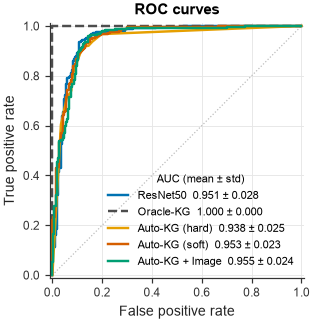

In [66]:
# ═══════════════════════════════════════════════════════════
# Fig 1: ROC 曲线
# ═══════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=SQUARE)
ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=0.8, ls=":")
for m in KEY_METHODS:
    fpr, tpr, _ = roc_curve(Y_OOF, oof_prob(m))
    st = STYLE[m]
    ax.plot(fpr, tpr, color=st["color"], ls=st["ls"],
            label=f"{st['short']}  {AUC_STATS.loc[m, 'mean']:.3f} ± {AUC_STATS.loc[m, 'std']:.3f}")
ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.01), xlabel="False positive rate", ylabel="True positive rate",
       title="ROC curves")
ax.set_aspect("equal")
ax.legend(loc="lower right", title="AUC (mean ± std)", title_fontsize=7.5)
save(fig, "fig01_roc")

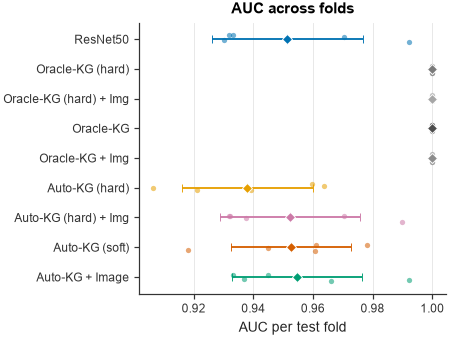

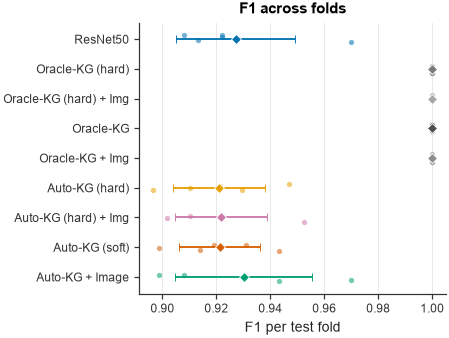

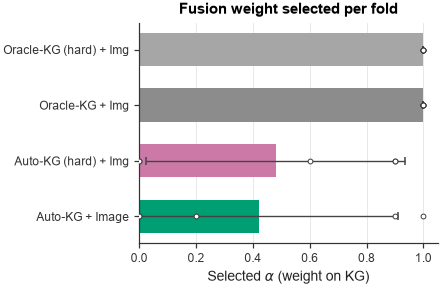

In [67]:
# ═══════════════════════════════════════════════════════════
# Fig 2a/2b: 各折 AUC 与 F1（点 = 单折，菱形 = 均值 ± 标准差）
# Fig 2c: 各融合方案在每折选出的 alpha
# ═══════════════════════════════════════════════════════════
order = list(AUC_STATS.index)
for tag, metric in [("a", "AUC"), ("b", "F1")]:
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    for i, m in enumerate(order):
        v = res.loc[[m], metric].values
        jit = np.random.default_rng(i).uniform(-0.15, 0.15, len(v))
        ax.scatter(v, np.full(len(v), i) + jit, s=12, color=STYLE[m]["color"], alpha=0.55, lw=0, zorder=2)
        ax.errorbar(v.mean(), i, xerr=v.std(), fmt="D", ms=4.5, color=STYLE[m]["color"], mec="white",
                    mew=0.6, ecolor=STYLE[m]["color"], elinewidth=1.2, capsize=2.5, zorder=3)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([short(m) for m in order])
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set(xlabel=f"{metric} per test fold", title=f"{metric} across folds")
    save(fig, f"fig02{tag}_{metric.lower()}_per_fold")

fused = [m for m in order if m.endswith("+ Image")]
al = res.loc[fused, "alpha"].groupby(level=0, sort=False)
fig, ax = plt.subplots(figsize=SINGLE)
bars = ax.barh([short(m) for m in fused], al.mean().values, xerr=al.std().values, height=0.6,
               color=[STYLE[m]["color"] for m in fused], error_kw=dict(lw=0.9, capsize=2.5, ecolor="#444444"))
for i, m in enumerate(fused):
    ax.scatter(res.loc[[m], "alpha"].values, np.full(len(res.loc[[m]]), i), s=10, color="white",
               edgecolor="#333333", lw=0.6, zorder=3)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(xlim=(0, 1.05), xlabel=r"Selected $\alpha$ (weight on KG)", title="Fusion weight selected per fold")
save(fig, "fig02c_alpha_per_fold")

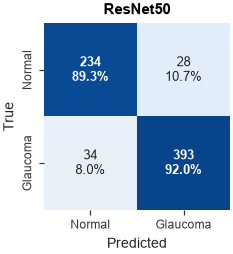

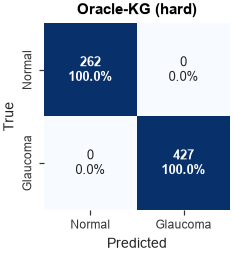

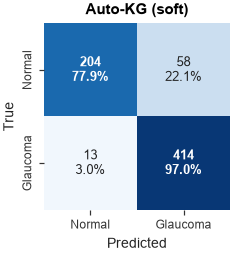

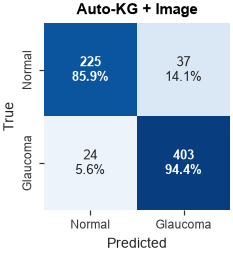

In [68]:
# ═══════════════════════════════════════════════════════════
# Fig 3a–3d: 混淆矩阵（阈值 0.5），每个方法一张
# ═══════════════════════════════════════════════════════════
for tag, m in zip("abcd", ["Image only (ResNet50)", "Oracle-KG (hard)", "Auto-KG (soft)", "Auto-KG (soft) + Image"]):
    cm = confusion_matrix(Y_OOF, (oof_prob(m) >= 0.5).astype(int))
    pct = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=SMALL)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}\n{pct[i, j]:.1%}", ha="center", va="center", fontsize=8.5,
                color="white" if pct[i, j] > 0.55 else "#222222", fontweight="bold" if i == j else "normal")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Glaucoma"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Glaucoma"], rotation=90, va="center")
    ax.set(xlabel="Predicted", ylabel="True", title=short(m))
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    save(fig, f"fig03{tag}_confusion_{short(m).replace(' ', '_').replace('+', 'plus').replace('(', '').replace(')', '').lower()}")

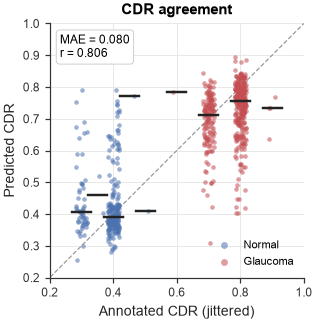

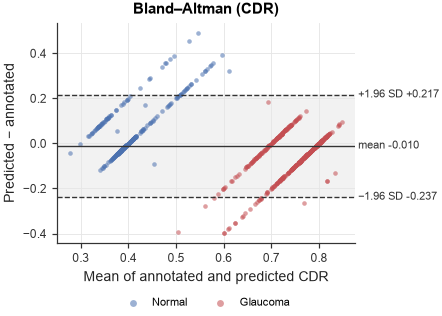

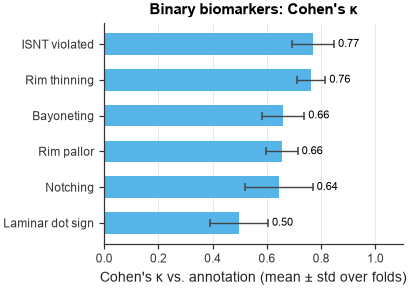

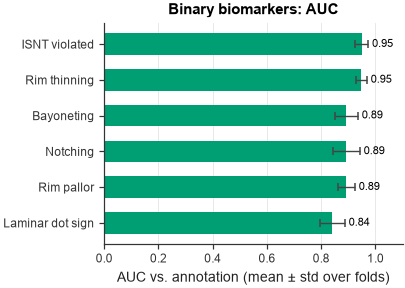

In [69]:
# ═══════════════════════════════════════════════════════════
# Fig 4a: 预测 CDR vs 标注 CDR    Fig 4b: Bland-Altman
# Fig 4c: 二值征象的 Cohen's kappa    Fig 4d: 二值征象的 AUC
# ═══════════════════════════════════════════════════════════
ok = ANN_OOF["cdr"].notna().values
a_cdr, p_cdr = ANN_OOF["cdr"].values[ok], PRED_OOF["cdr"].values[ok]
yk = Y_OOF[ok]
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=SQUARE)
ax.plot([0, 1], [0, 1], color="#999999", lw=0.8, ls="--", zorder=1)
for lab in [0, 1]:
    s = yk == lab
    ax.scatter(a_cdr[s] + rng.uniform(-0.018, 0.018, s.sum()), p_cdr[s], s=9, alpha=0.55, lw=0,
               color=CLS_COLORS[lab], label=CLS_NAMES[lab], zorder=2)
for v in np.unique(a_cdr):                       # 每个标注取值上的中位数
    ax.plot([v - 0.03, v + 0.03], [np.median(p_cdr[a_cdr == v])] * 2, color="#222222", lw=1.6, zorder=3)
ax.text(0.04, 0.96, f"MAE = {np.mean(np.abs(a_cdr - p_cdr)):.3f}\nr = {pearsonr(a_cdr, p_cdr)[0]:.3f}",
        transform=ax.transAxes, va="top", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#CCCCCC", lw=0.6))
ax.set(xlim=(0.2, 1.0), ylim=(0.2, 1.0), xlabel="Annotated CDR (jittered)", ylabel="Predicted CDR",
       title="CDR agreement")
ax.set_aspect("equal")
ax.legend(loc="lower right", markerscale=1.5)
save(fig, "fig04a_cdr_scatter")

mean_, diff = (a_cdr + p_cdr) / 2, p_cdr - a_cdr
md, sd = diff.mean(), diff.std()
fig, ax = plt.subplots(figsize=SINGLE)
ax.axhspan(md - 1.96 * sd, md + 1.96 * sd, color="#F2F2F2", zorder=0)
for lab in [0, 1]:
    s = yk == lab
    ax.scatter(mean_[s], diff[s], s=9, alpha=0.55, lw=0, color=CLS_COLORS[lab], label=CLS_NAMES[lab])
for v, ls, txt in [(md, "-", f"mean {md:+.3f}"), (md + 1.96 * sd, "--", f"+1.96 SD {md + 1.96 * sd:+.3f}"),
                   (md - 1.96 * sd, "--", f"−1.96 SD {md - 1.96 * sd:+.3f}")]:
    ax.axhline(v, color="#333333", lw=0.9, ls=ls)
    ax.text(1.0, v, " " + txt, transform=ax.get_yaxis_transform(), va="center", fontsize=7, color="#333333")
ax.set(xlabel="Mean of annotated and predicted CDR", ylabel="Predicted − annotated", title="Bland–Altman (CDR)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, markerscale=1.5)
save(fig, "fig04b_cdr_bland_altman")

ag = pd.DataFrame(agree)
for tag, suffix, xlabel, col in [("c", "kappa", "Cohen's κ", "#56B4E9"), ("d", "AUC", "AUC", "#009E73")]:
    v = ag[[f"{c} {suffix}" for c in BIN_COLS]]
    mu, sdv = v.mean().values, v.std().values
    order_ = np.argsort(mu)
    fig, ax = plt.subplots(figsize=SINGLE)
    bars = ax.barh([BM_NAMES[BIN_COLS[i]] for i in order_], mu[order_], xerr=sdv[order_], height=0.6, color=col,
                   error_kw=dict(lw=0.9, capsize=2.5, ecolor="#444444"))
    for b, m_, s_ in zip(bars, mu[order_], sdv[order_]):
        ax.text(m_ + s_ + 0.015, b.get_y() + b.get_height() / 2, f"{m_:.2f}", va="center", fontsize=7)
    ax.grid(axis="y", visible=False)
    ax.set(xlim=(0, 1.1), xlabel=f"{xlabel} vs. annotation (mean ± std over folds)",
           title=f"Binary biomarkers: {xlabel}")
    save(fig, f"fig04{tag}_binary_{suffix.lower()}")

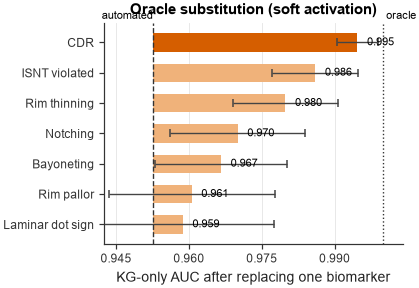

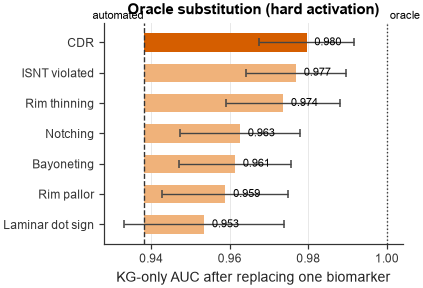

In [70]:
# ═══════════════════════════════════════════════════════════
# Fig 5a / 5b: 逐个 oracle 替换（软激活 / 硬激活）
#   横条 = 把该生物标志物换回标注后的 KG-only AUC；虚线 = 不替换；点线 = 全部替换
# ═══════════════════════════════════════════════════════════
sb = pd.DataFrame(subst)
single_cols = [c for c in sb.columns if c.startswith("Oracle ") and c != "Oracle (all replaced)"]
for tag, mode in [("a", "soft"), ("b", "hard")]:
    v = sb[sb["mode"] == mode]
    mu, sdv = v[single_cols].mean(), v[single_cols].std()
    order_ = mu.sort_values().index
    base, full = v["Auto (none replaced)"].mean(), v["Oracle (all replaced)"].mean()
    fig, ax = plt.subplots(figsize=SINGLE)
    names = [BM_NAMES.get(c.replace("Oracle ", ""), c.replace("Oracle ", "")) for c in order_]
    colors = ["#D55E00" if "cdr" in c else "#F0B27A" for c in order_]
    bars = ax.barh(names, mu[order_] - base, left=base, height=0.6, color=colors,
                   xerr=sdv[order_], error_kw=dict(lw=0.9, capsize=2.5, ecolor="#444444"))
    for b, m_ in zip(bars, mu[order_]):
        ax.text(m_ + 0.002, b.get_y() + b.get_height() / 2, f"{m_:.3f}", va="center", fontsize=7)
    ax.axvline(base, color="#333333", lw=0.9, ls="--")
    ax.axvline(full, color="#333333", lw=0.9, ls=":")
    ax.text(base, 1.01, " automated", transform=ax.get_xaxis_transform(), fontsize=7, ha="right", va="bottom")
    ax.text(full, 1.01, " oracle", transform=ax.get_xaxis_transform(), fontsize=7, ha="left", va="bottom")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(base - 0.01, min(1.004, full + 0.006))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.set(xlabel="KG-only AUC after replacing one biomarker", title=f"Oracle substitution ({mode} activation)")
    save(fig, f"fig05{tag}_oracle_substitution_{mode}")

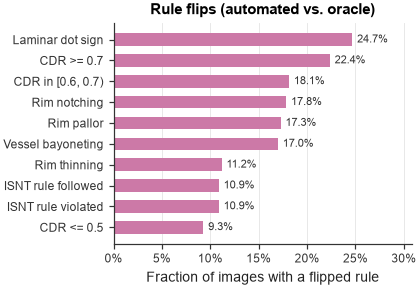

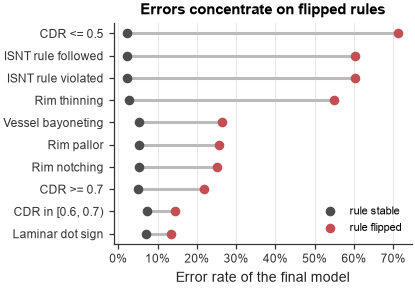

In [71]:
# ═══════════════════════════════════════════════════════════
# Fig 6a: 每条规则的翻转率
# Fig 6b: 规则翻转与否时最终模型的错误率（哑铃图）
# ═══════════════════════════════════════════════════════════
ft = flip_tab.copy()
ft.index = [RULE_NAMES.get(i, i) for i in ft.index]
o = ft["flip_rate"].sort_values().index
fig, ax = plt.subplots(figsize=SINGLE)
bars = ax.barh(o, ft.loc[o, "flip_rate"], height=0.6, color="#CC79A7")
hbar_labels(ax, bars, fmt="{:.1%}", pad=0.005)
ax.grid(axis="y", visible=False)
ax.set(xlim=(0, ft["flip_rate"].max() * 1.25), xlabel="Fraction of images with a flipped rule",
       title="Rule flips (automated vs. oracle)")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
save(fig, "fig06a_rule_flip_rate")

o = (ft["err_if_flip"] - ft["err_if_stable"]).sort_values().index
fig, ax = plt.subplots(figsize=SINGLE)
for i, r in enumerate(o):
    a_, b_ = ft.loc[r, "err_if_stable"], ft.loc[r, "err_if_flip"]
    ax.plot([a_, b_], [i, i], color="#BBBBBB", lw=2, zorder=1)
    ax.scatter(a_, i, s=28, color="#4D4D4D", zorder=2, label="rule stable" if i == 0 else None)
    ax.scatter(b_, i, s=28, color="#C44E52", zorder=2, label="rule flipped" if i == 0 else None)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set(xlabel="Error rate of the final model", title="Errors concentrate on flipped rules")
ax.legend(loc="lower right")
save(fig, "fig06b_error_flip_vs_stable")

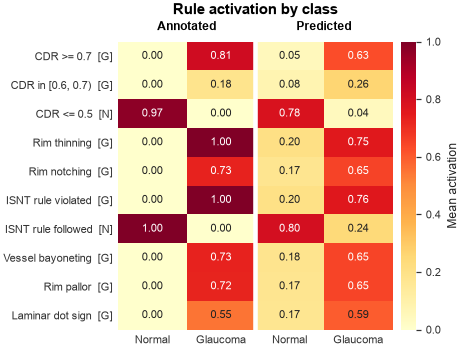

In [72]:
# ═══════════════════════════════════════════════════════════
# Fig 7: 规则平均激活热图（按类别；左两列标注，右两列预测）
# ═══════════════════════════════════════════════════════════
act_ann = rule_activations(ANN_OOF, CFG, "soft")
act_pred = rule_activations(PRED_OOF, CFG, "soft")
H = pd.DataFrame({"Normal": act_ann[Y_OOF == 0].mean(), "Glaucoma": act_ann[Y_OOF == 1].mean(),
                  "Normal ": act_pred[Y_OOF == 0].mean(), "Glaucoma ": act_pred[Y_OOF == 1].mean()})
fig, ax = plt.subplots(figsize=(3.5, 3.4))
im = ax.imshow(H.values, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(H.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else "#222222")
ax.set_xticks(range(4)); ax.set_xticklabels(["Normal", "Glaucoma", "Normal", "Glaucoma"], fontsize=7.5)
ax.set_yticks(range(len(RULES)))
ax.set_yticklabels([f"{r['name']}  [{'G' if r['evidence'] > 0 else 'N'}]" for r in RULES], fontsize=7.5)
ax.axvline(1.5, color="white", lw=3)
ax.text(0.5, -0.9, "Annotated", ha="center", fontsize=8, fontweight="bold")
ax.text(2.5, -0.9, "Predicted", ha="center", fontsize=8, fontweight="bold")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
cb.set_label("Mean activation", fontsize=8); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7)
ax.set_title("Rule activation by class", pad=18)
save(fig, "fig07_rule_activation_heatmap")

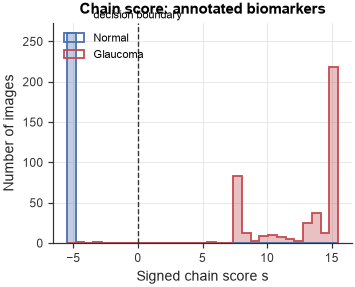

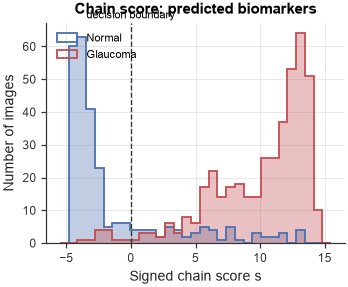

In [73]:
# ═══════════════════════════════════════════════════════════
# Fig 8a / 8b: 带符号链分数分布（标注 / 预测）
# ═══════════════════════════════════════════════════════════
s_ann, s_pred = signed_score(act_ann, CFG), signed_score(act_pred, CFG)
bins = np.linspace(min(s_ann.min(), s_pred.min()) - 0.5, max(s_ann.max(), s_pred.max()) + 0.5, 32)
for tag, s, t in [("a", s_ann, "Chain score: annotated biomarkers"), ("b", s_pred, "Chain score: predicted biomarkers")]:
    fig, ax = plt.subplots(figsize=SINGLE)
    for lab in [0, 1]:
        ax.hist(s[Y_OOF == lab], bins=bins, color=CLS_COLORS[lab], alpha=0.35, lw=0)
        ax.hist(s[Y_OOF == lab], bins=bins, color=CLS_COLORS[lab], histtype="step", lw=1.2, label=CLS_NAMES[lab])
    ax.axvline(0, color="#333333", lw=0.9, ls="--")
    ax.text(0, 1.01, "decision boundary", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
    ax.set(xlabel="Signed chain score s", ylabel="Number of images", title=t)
    ax.legend(loc="upper left")
    save(fig, f"fig08{tag}_chain_score_{'annotated' if tag == 'a' else 'predicted'}")

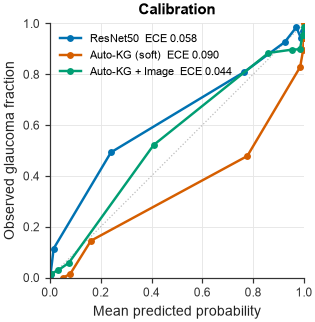

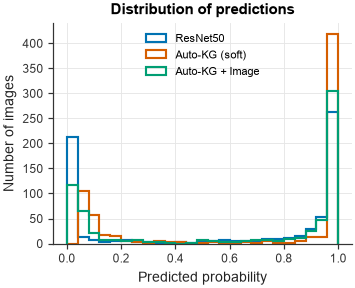

In [74]:
# ═══════════════════════════════════════════════════════════
# Fig 9a: 校准曲线    Fig 9b: 预测概率分布
# ═══════════════════════════════════════════════════════════
cal_methods = ["Image only (ResNet50)", "Auto-KG (soft)", "Auto-KG (soft) + Image"]
fig, ax = plt.subplots(figsize=SQUARE)
ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=0.8, ls=":")
for m in cal_methods:
    p = oof_prob(m)
    frac, mp = calibration_curve(Y_OOF, p, n_bins=10, strategy="quantile")
    ax.plot(mp, frac, marker="o", ms=3.5, color=STYLE[m]["color"], label=f"{short(m)}  ECE {ece(Y_OOF, p):.3f}")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed glaucoma fraction",
       title="Calibration")
ax.set_aspect("equal")
ax.legend(loc="upper left")
save(fig, "fig09a_calibration")

fig, ax = plt.subplots(figsize=SINGLE)
for m in cal_methods:
    ax.hist(oof_prob(m), bins=25, range=(0, 1), histtype="step", lw=1.4, color=STYLE[m]["color"], label=short(m))
ax.set(xlabel="Predicted probability", ylabel="Number of images", title="Distribution of predictions")
ax.legend(loc="upper center")
save(fig, "fig09b_prediction_histogram")

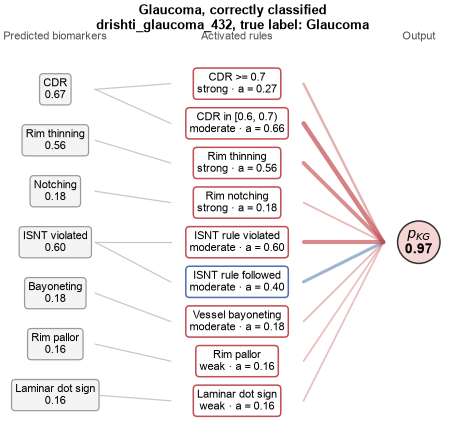

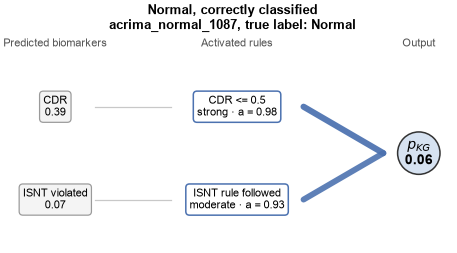

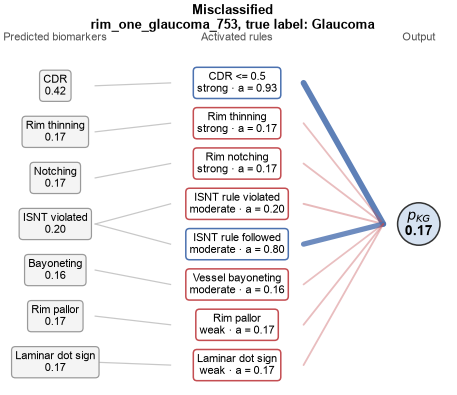

In [75]:
# ═══════════════════════════════════════════════════════════
# Fig 10a–10c: 推理链示意（正确的青光眼、正确的正常、误判各一例，每例一张）
#   左：预测生物标志物；中：激活的规则（线宽 = 激活值）；右：KG 概率
# ═══════════════════════════════════════════════════════════
from matplotlib.patches import FancyBboxPatch

def draw_chain(bm_row, title):
    act = rule_activations(bm_row.to_frame().T.astype(float), CFG, "soft").iloc[0]
    p = kg_probability(bm_row.to_frame().T.astype(float), CFG, "soft")[0]
    used = [r for r in RULES if act[r["id"]] >= 0.1]
    bms = list(dict.fromkeys(r["bm"] for r in used))
    yb = {b: 1 - (i + 0.5) / max(len(bms), 1) for i, b in enumerate(bms)}
    yr = {r["id"]: 1 - (i + 0.5) / max(len(used), 1) for i, r in enumerate(used)}
    fig, ax = plt.subplots(figsize=(5.2, 0.42 * max(len(used), 4) + 0.6))
    for r in used:
        a = act[r["id"]]
        col = EVID_COLORS[r["evidence"]]
        ax.plot([0.19, 0.36], [yb[r["bm"]], yr[r["id"]]], color="#C8C8C8", lw=0.8, zorder=1)
        ax.plot([0.66, 0.84], [yr[r["id"]], 0.5], color=col, lw=0.6 + 3.5 * a, alpha=0.25 + 0.7 * a,
                solid_capstyle="round", zorder=1)
        ax.text(0.51, yr[r["id"]], f"{r['name']}\n{r['strength']} · a = {a:.2f}", ha="center", va="center",
                fontsize=7, zorder=3, bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=col, lw=1.0))
    for b in bms:
        ax.text(0.10, yb[b], f"{BM_NAMES[b]}\n{float(bm_row[b]):.2f}", ha="center", va="center", fontsize=7,
                zorder=3, bbox=dict(boxstyle="round,pad=0.35", fc="#F4F4F4", ec="#9A9A9A", lw=0.8))
    fc = "#F6D5D5" if p >= 0.5 else "#D6E2F1"
    ax.text(0.92, 0.5, f"$p_{{KG}}$\n{p:.2f}", ha="center", va="center", fontsize=9, fontweight="bold", zorder=3,
            bbox=dict(boxstyle="circle,pad=0.45", fc=fc, ec="#333333", lw=1.0))
    for x_, t_ in [(0.10, "Predicted biomarkers"), (0.51, "Activated rules"), (0.92, "Output")]:
        ax.text(x_, 1.04, t_, ha="center", va="bottom", fontsize=7.5, color="#555555", transform=ax.transAxes)
    ax.set(xlim=(0, 1), ylim=(-0.02, 1.02))
    ax.axis("off")
    ax.set_title(title, pad=18, fontsize=8.5)
    return fig

p_fin = oof_prob("Auto-KG (soft) + Image")
correct = (p_fin >= 0.5).astype(int) == Y_OOF
cases = [("a", "glaucoma_correct", "Glaucoma, correctly classified", np.where(correct & (Y_OOF == 1))[0]),
         ("b", "normal_correct", "Normal, correctly classified", np.where(correct & (Y_OOF == 0))[0]),
         ("c", "misclassified", "Misclassified", np.where(~correct)[0])]
for tag, fname, title, idx in cases:
    if len(idx) == 0:
        continue
    i = idx[0]
    fig = draw_chain(PRED_OOF.iloc[i], f"{title}\n{IDS_OOF[i]}, true label: {CLS_NAMES[Y_OOF[i]]}")
    save(fig, f"fig10{tag}_reasoning_chain_{fname}")

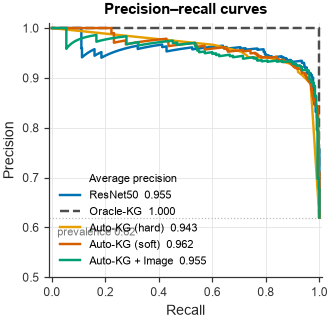

In [76]:
# ═══════════════════════════════════════════════════════════
# Fig 11: Precision–Recall 曲线
# ═══════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=SQUARE)
ax.axhline(Y_OOF.mean(), color="#BBBBBB", lw=0.8, ls=":")
ax.text(0.02, Y_OOF.mean() - 0.02, f"prevalence {Y_OOF.mean():.2f}", fontsize=7, va="top", color="#777777")
for m in KEY_METHODS:
    pr, rc, _ = precision_recall_curve(Y_OOF, oof_prob(m))
    ax.plot(rc, pr, color=STYLE[m]["color"], ls=STYLE[m]["ls"],
            label=f"{short(m)}  {average_precision_score(Y_OOF, oof_prob(m)):.3f}")
ax.set(xlim=(-0.01, 1.01), ylim=(0.5, 1.01), xlabel="Recall", ylabel="Precision", title="Precision–recall curves")
ax.legend(loc="lower left", title="Average precision", title_fontsize=7.5)
save(fig, "fig11_pr_curves")

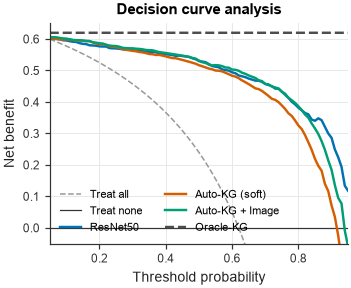

In [77]:
# ═══════════════════════════════════════════════════════════
# Fig 12: 决策曲线分析（净获益）
# ═══════════════════════════════════════════════════════════
th = np.linspace(0.05, 0.95, 91)
prev = Y_OOF.mean()
fig, ax = plt.subplots(figsize=SINGLE)
ax.plot(th, prev - (1 - prev) * th / (1 - th), color="#999999", lw=1.0, ls="--", label="Treat all")
ax.axhline(0, color="#333333", lw=0.8, label="Treat none")
for m in ["Image only (ResNet50)", "Auto-KG (soft)", "Auto-KG (soft) + Image", "Oracle-KG (soft)"]:
    ax.plot(th, net_benefit(Y_OOF, oof_prob(m), th), color=STYLE[m]["color"], ls=STYLE[m]["ls"], label=short(m))
ax.set(xlim=(0.05, 0.95), ylim=(-0.05, prev + 0.03), xlabel="Threshold probability", ylabel="Net benefit",
       title="Decision curve analysis")
ax.legend(loc="lower left", ncol=2)
save(fig, "fig12_decision_curve")

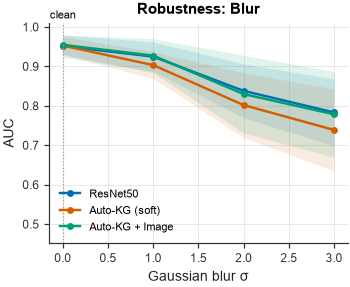

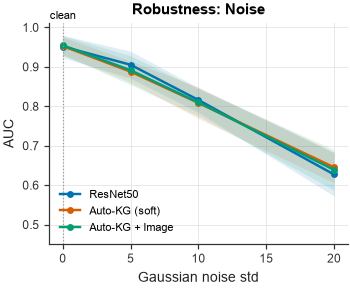

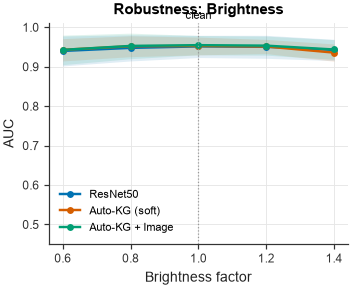

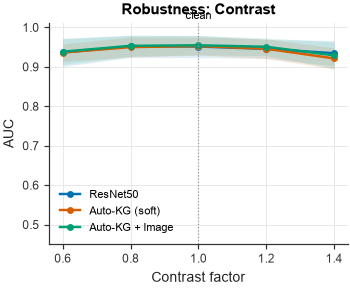

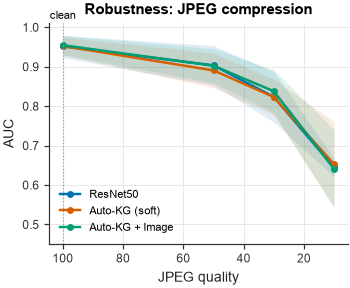

In [78]:
# ═══════════════════════════════════════════════════════════
# Fig 13a–13e: 图像扰动鲁棒性，每类扰动一张（各折均值 ± 标准差）
# ═══════════════════════════════════════════════════════════
rob = pd.DataFrame(robust)
ROB_METHODS = ["Image only", "Auto-KG (soft)", "Auto-KG (soft) + Image"]
ROB_STYLE = {"Image only": STYLE["Image only (ResNet50)"], "Auto-KG (soft)": STYLE["Auto-KG (soft)"],
             "Auto-KG (soft) + Image": STYLE["Auto-KG (soft) + Image"]}
XLABEL = {"gaussian_blur": "Gaussian blur σ", "gaussian_noise": "Gaussian noise std", "brightness": "Brightness factor",
          "contrast": "Contrast factor", "jpeg": "JPEG quality"}
TITLE = {"gaussian_blur": "Blur", "gaussian_noise": "Noise", "brightness": "Brightness",
         "contrast": "Contrast", "jpeg": "JPEG compression"}
ymin = max(0.4, rob[ROB_METHODS].min().min() - 0.05)
for tag, kind in zip("abcdefgh", CFG.robustness):
    sub = rob[rob.perturbation.isin(["none", kind])].copy()
    sub["x"] = np.where(sub.perturbation == "none", CLEAN_LEVEL[kind], sub.level).astype(float)
    fig, ax = plt.subplots(figsize=SINGLE)
    for k, m in enumerate(ROB_METHODS):
        g = sub.groupby("x")[m].agg(["mean", "std"]).sort_index()
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=ROB_STYLE[m]["color"],
                        alpha=0.12, lw=0)
        ax.plot(g.index, g["mean"], marker="o", ms=3.5, color=ROB_STYLE[m]["color"], label=ROB_STYLE[m]["short"])
    ax.axvline(CLEAN_LEVEL[kind], color="#999999", lw=0.8, ls=":")
    ax.text(CLEAN_LEVEL[kind], 1.01, "clean", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
    if kind == "jpeg":
        ax.invert_xaxis()
    ax.set(ylim=(ymin, 1.01), xlabel=XLABEL[kind], ylabel="AUC", title=f"Robustness: {TITLE[kind]}")
    ax.legend(loc="lower left")
    save(fig, f"fig13{tag}_robustness_{kind}")

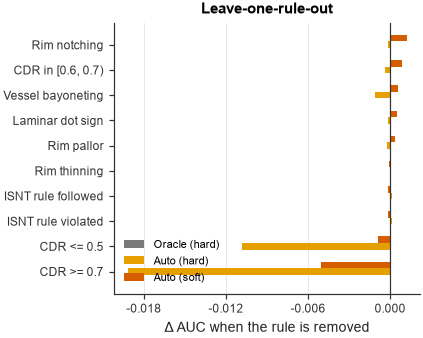

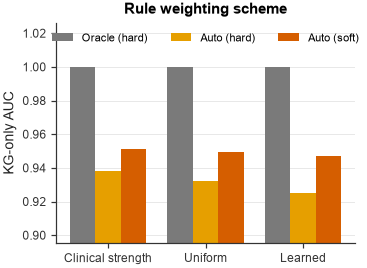

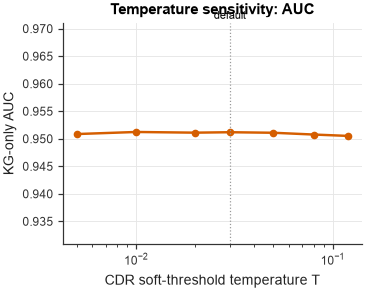

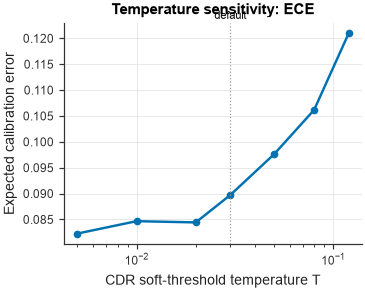

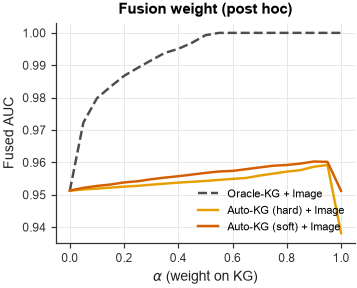

In [79]:
# ═══════════════════════════════════════════════════════════
# Fig 14a: 逐条去规则    Fig 14b: 规则权重方案
# Fig 14c: 温度 vs AUC    Fig 14d: 温度 vs ECE    Fig 14e: 融合权重曲线
# ═══════════════════════════════════════════════════════════
ABL = [("Oracle (hard)", "#7A7A7A"), ("Auto (hard)", "#E69F00"), ("Auto (soft)", "#D55E00")]

d = loro.drop(index="none (full KG)")
d.index = [RULE_NAMES.get(i, i) for i in d.index]
o = d["Delta Auto (soft)"].sort_values().index
yy = np.arange(len(o))
fig, ax = plt.subplots(figsize=(3.6, 3.2))
for k, (n, col) in enumerate(ABL):
    ax.barh(yy + (k - 1) * 0.26, d.loc[o, f"Delta {n}"], 0.26, color=col, label=n)
ax.set_yticks(yy); ax.set_yticklabels(o)
ax.axvline(0, color="#333333", lw=0.8)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_locator(MaxNLocator(4)); ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
ax.set(xlabel="Δ AUC when the rule is removed", title="Leave-one-rule-out")
ax.legend(loc="lower left")
save(fig, "fig14a_leave_one_rule_out")

fig, ax = plt.subplots(figsize=SINGLE)
x = np.arange(len(weights_tab))
for k, (n, col) in enumerate(ABL):
    b = ax.bar(x + (k - 1) * 0.26, weights_tab[n], 0.26, color=col, label=n)
lo_ = max(0.5, weights_tab.values.min() - 0.03)
ax.set_xticks(x); ax.set_xticklabels([s.split(" (")[0] for s in weights_tab.index])
ax.grid(axis="x", visible=False)
ax.set(ylim=(lo_, 1.0 + (1.0 - lo_) * 0.25), ylabel="KG-only AUC", title="Rule weighting scheme")
ax.legend(loc="upper center", ncol=3)
save(fig, "fig14b_rule_weighting")

for tag, col_, ylabel, color in [("c", "AUC", "KG-only AUC", "#D55E00"), ("d", "ECE", "Expected calibration error", "#0072B2")]:
    fig, ax = plt.subplots(figsize=SINGLE)
    ax.plot(temp_tab.index, temp_tab[col_], marker="o", color=color)
    ax.axvline(CFG.soft_T_cdr, color="#999999", lw=0.8, ls=":")
    ax.text(CFG.soft_T_cdr, 1.01, "default", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7)
    ax.set_xscale("log")
    if col_ == "AUC":
        mid = temp_tab["AUC"].mean()
        ax.set_ylim(mid - 0.02, mid + 0.02)
    ax.set(xlabel="CDR soft-threshold temperature T", ylabel=ylabel, title=f"Temperature sensitivity: {col_}")
    save(fig, f"fig14{tag}_temperature_{col_.lower()}")

fig, ax = plt.subplots(figsize=SINGLE)
for v in ["Oracle-KG (soft)", "Auto-KG (hard)", "Auto-KG (soft)"]:
    ax.plot(alpha_curve.index, alpha_curve[f"{v} AUC"], color=STYLE[v]["color"], ls=STYLE[v]["ls"],
            label=f"{short(v)} + Image")
ax.set(xlabel=r"$\alpha$ (weight on KG)", ylabel="Fused AUC", title="Fusion weight (post hoc)")
ax.legend(loc="lower right")
save(fig, "fig14e_fusion_weight_curve")

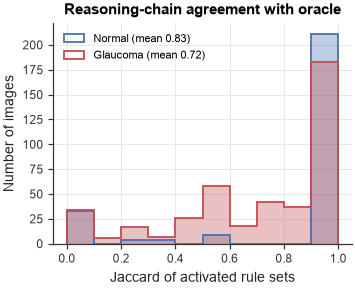

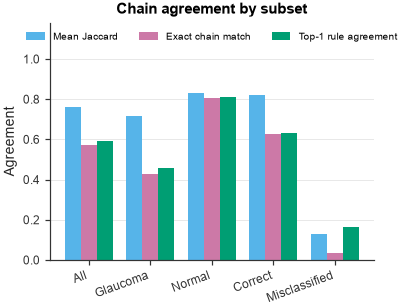

In [80]:
# ═══════════════════════════════════════════════════════════
# Fig 15a: 推理链 Jaccard 分布    Fig 15b: 各子集的一致性
# ═══════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=SINGLE)
bins = np.linspace(0, 1, 11)
for lab in [0, 1]:
    ax.hist(JACC[Y_OOF == lab], bins=bins, color=CLS_COLORS[lab], alpha=0.35, lw=0)
    ax.hist(JACC[Y_OOF == lab], bins=bins, color=CLS_COLORS[lab], histtype="step", lw=1.2,
            label=f"{CLS_NAMES[lab]} (mean {JACC[Y_OOF == lab].mean():.2f})")
ax.set(xlabel="Jaccard of activated rule sets", ylabel="Number of images",
       title="Reasoning-chain agreement with oracle")
ax.legend(loc="upper left")
save(fig, "fig15a_chain_jaccard_hist")

fig, ax = plt.subplots(figsize=(3.8, 2.8))
x = np.arange(len(expl))
for k, (c, col) in enumerate([("Mean Jaccard", "#56B4E9"), ("Exact chain match", "#CC79A7"),
                              ("Top-1 rule agreement", "#009E73")]):
    ax.bar(x + (k - 1) * 0.26, expl[c], 0.26, color=col, label=c)
ax.set_xticks(x); ax.set_xticklabels(expl.index.str.replace(" (final)", ""), rotation=20, ha="right")
ax.grid(axis="x", visible=False)
ax.set(ylim=(0, 1.18), ylabel="Agreement", title="Chain agreement by subset")
ax.legend(loc="upper center", ncol=3, fontsize=6.8)
save(fig, "fig15b_chain_agreement_by_subset")

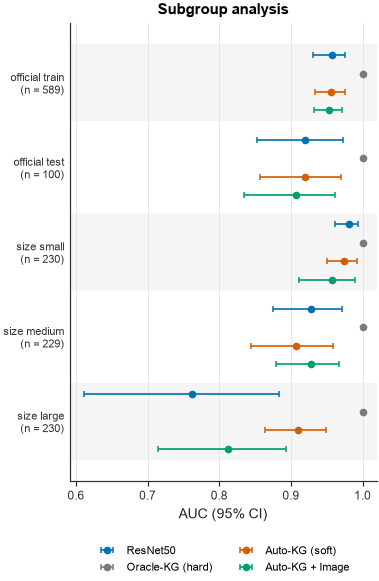

In [81]:
# ═══════════════════════════════════════════════════════════
# Fig 16: 亚组分析森林图（AUC 与 95% 置信区间）
# ═══════════════════════════════════════════════════════════
sg_names = list(SUBGROUPS)
fig, ax = plt.subplots(figsize=(3.6, 0.42 * len(sg_names) * len(SUB_METHODS) / 2 + 1.2))
ypos, ticks = 0, []
for gi, sg in enumerate(sg_names):
    start = ypos
    if gi % 2 == 0:
        ax.axhspan(ypos - 0.6, ypos + len(SUB_METHODS) - 0.4, color="#F5F5F5", zorder=0, lw=0)
    for meth in SUB_METHODS:
        r = subgroup[(subgroup.Subgroup == sg) & (subgroup.Method == meth)].iloc[0]
        if not np.isnan(r.AUC):
            ax.errorbar(r.AUC, ypos, xerr=[[r.AUC - r["CI low"]], [r["CI high"] - r.AUC]], fmt="o", ms=4,
                        color=STYLE[meth]["color"], elinewidth=1.1, capsize=2,
                        label=short(meth) if gi == 0 else None, zorder=2)
        ypos += 1
    ticks.append(((start + ypos - 1) / 2, f"{sg}\n(n = {int(r.N)})"))
    ypos += 0.6
ax.set_yticks([t for t, _ in ticks]); ax.set_yticklabels([l for _, l in ticks], fontsize=7.5)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set(xlabel="AUC (95% CI)", title="Subgroup analysis")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
save(fig, "fig16_subgroup_forest")

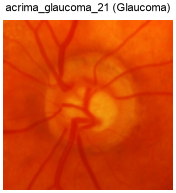

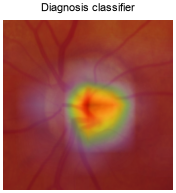

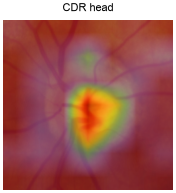

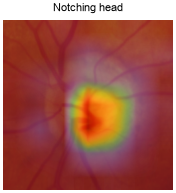

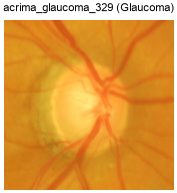

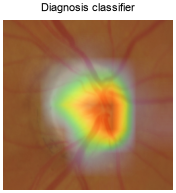

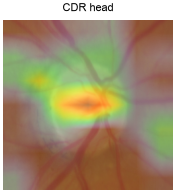

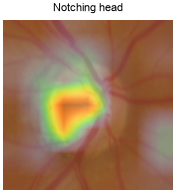

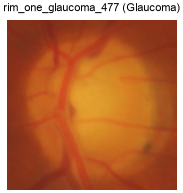

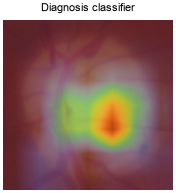

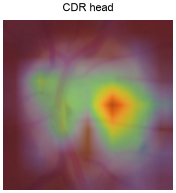

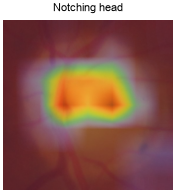

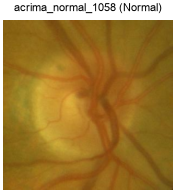

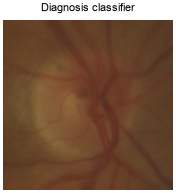

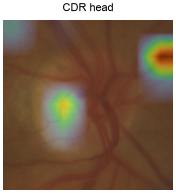

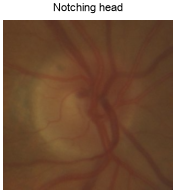

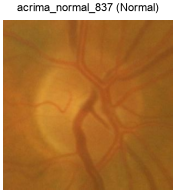

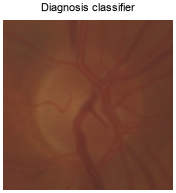

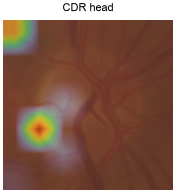

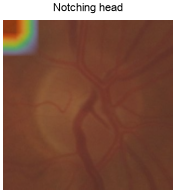

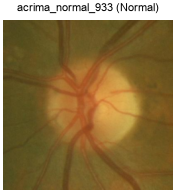

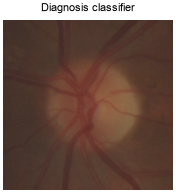

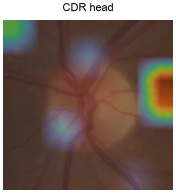

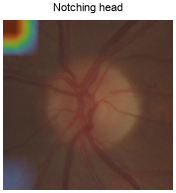

In [82]:
# ═══════════════════════════════════════════════════════════
# Fig 17: Grad-CAM，每张图像、每个输出头单独保存（MOCK 模式跳过）
#   文件名：fig17_<图像id>_<original|diagnosis|cdr|notching>
# ═══════════════════════════════════════════════════════════
if MOCK:
    print("MOCK 模式，跳过 Grad-CAM")
else:
    p_, te_ = LAST["pipe"], LAST["te"]
    yt = y[te_]
    pick = list(te_[yt == 1][: CFG.n_gradcam // 2]) + list(te_[yt == 0][: CFG.n_gradcam - CFG.n_gradcam // 2])
    heads = [("diagnosis", "Diagnosis classifier", p_.cls, 0), ("cdr", "CDR head", p_.bm, 0),
             ("notching", "Notching head", p_.bm, BM_COLS.index("notching"))]
    for i in pick:
        img = IMGS[i]
        fig, ax = plt.subplots(figsize=(2.0, 2.0))
        ax.imshow(img); ax.axis("off")
        ax.set_title(f"{meta.id[i]} ({CLS_NAMES[y[i]]})", fontsize=7.5, fontweight="normal")
        save(fig, f"fig17_{meta.id[i]}_original")
        for key, title, model, oi in heads:
            cam = gradcam(model, img, oi, CFG.img_size, p_.device)
            fig, ax = plt.subplots(figsize=(2.0, 2.0))
            ax.imshow(img)
            ax.imshow(cam, cmap="turbo", alpha=0.45, vmin=0, vmax=1)
            ax.axis("off")
            ax.set_title(title, fontsize=7.5, fontweight="normal")
            save(fig, f"fig17_{meta.id[i]}_{key}")

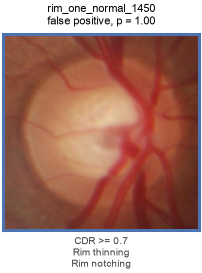

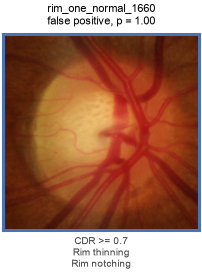

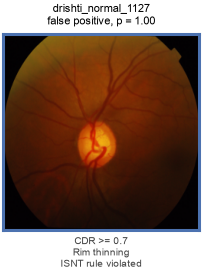

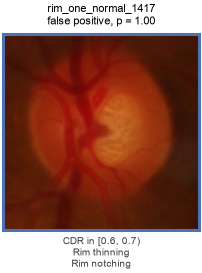

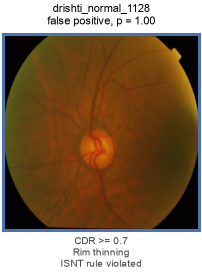

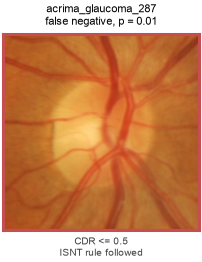

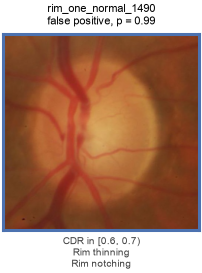

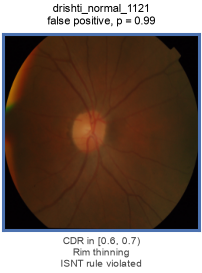

In [83]:
# ═══════════════════════════════════════════════════════════
# Fig 18: 误判病例，每例单独保存（图像 + 概率 + 主要激活规则）
# ═══════════════════════════════════════════════════════════
show = err.sort_values("p_final", key=lambda s: (s - 0.5).abs(), ascending=False).head(8)
if len(show) == 0:
    print("没有误判病例")
for k, (_, r) in enumerate(show.iterrows()):
    fig, ax = plt.subplots(figsize=(2.3, 2.9))
    ax.imshow(IMGS[POS[r.id]]); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_color("#C44E52" if r.error_type == "false negative" else "#4C72B0"); s.set_linewidth(2)
    chain = [c.split(" (")[0].split("] ")[-1] for c in r.chain_pred.split(" | ")][:3] if r.chain_pred else []
    ax.set_title(f"{r.id}\n{r.error_type}, p = {r.p_final:.2f}", fontsize=7.5, fontweight="normal")
    ax.set_xlabel("\n".join(chain) if chain else "no rule activated", fontsize=6.8, color="#444444")
    save(fig, f"fig18{chr(97 + k)}_misclassified_{r.id}")

In [84]:
# ═══════════════════════════════════════════════════════════
# Fig 19a / 19b: 额外消融（仅当已运行消融单元 A1–A3 时绘制）
# ═══════════════════════════════════════════════════════════
if "abl_score" in globals():
    sub = abl_score.loc["Auto (soft)"]
    fig, ax = plt.subplots(figsize=(3.8, 2.8))
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["AUC"], 0.4, color="#D55E00", label="AUC")
    ax.bar(x + 0.2, sub["BalAcc"], 0.4, color="#0072B2", label="Balanced accuracy")
    ax.set_xticks(x); ax.set_xticklabels(sub.index, rotation=30, ha="right", fontsize=7)
    ax.grid(axis="x", visible=False)
    ax.set(ylim=(0.4, 1.1), title="Chain-score form and mapping")
    ax.legend(loc="upper center", ncol=2)
    save(fig, "fig19a_score_mapping")
if "AWARE_OOF" in globals():
    fig, ax = plt.subplots(figsize=SINGLE)
    bins = np.linspace(0, 1, 41)
    for name, pred_, ls in [("label-blind", PRED_OOF, "-"), ("label-aware", AWARE_OOF, "--")]:
        for lab in [0, 1]:
            ax.hist(pred_["cdr"].values[Y_OOF == lab], bins=bins, histtype="step", lw=1.3, ls=ls,
                    color=CLS_COLORS[lab], label=f"{CLS_NAMES[lab]}, {name}")
    ax.set(xlabel="Predicted CDR", ylabel="Number of images", title="Predicted CDR: label-blind vs. label-aware")
    ax.legend(loc="upper left", fontsize=6.8)
    save(fig, "fig19b_cdr_blind_vs_aware")
if "abl_score" not in globals() and "AWARE_OOF" not in globals():
    print("尚未运行消融单元 A1–A3，跳过 Fig 19")

尚未运行消融单元 A1–A3，跳过 Fig 19


## 知识图谱可视化
- **Fig 20a–20f 构建过程**：以一张眼底图为例，逐步展示"一个图像节点如何长成一张推理子图，并接入全局知识图谱"
- **Fig 21 全局知识图谱**：直接读取 Cell 12 导出的 `kg_nodes_*.csv` / `kg_edges_*.csv`，画出最终构建的图（标注版与自动版各一张）及其统计
- **Fig 22 规则共激活网络**：规则之间同时被激活的频率，比较标注与预测生物标志物下的图结构

In [85]:
# ═══════════════════════════════════════════════════════════
# Cell KG0: 知识图谱绘图工具（节点、边、固定版式）
# ═══════════════════════════════════════════════════════════
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.patches import FancyBboxPatch

G_COL, N_COL = EVID_COLORS[+1], EVID_COLORS[-1]
BM_ORDER = BM_COLS
RULES_SORTED = sorted(RULES, key=lambda r: (BM_ORDER.index(r["bm"]), -r["evidence"]))

# 构建过程图的固定坐标（轴坐标）：图像 | 生物标志物 | 规则 | 证据汇总 | 输出
X_IMG, X_BM, X_RULE, X_EVI, X_OUT = 0.06, 0.255, 0.53, 0.76, 0.925
W_BM, H_BM = 0.155, 0.085
W_RULE, H_RULE = 0.215, 0.08
W_EVI, H_EVI = 0.12, 0.17
W_OUT, H_OUT = 0.14, 0.15
Y_BM = dict(zip(BM_ORDER, np.linspace(0.92, 0.08, len(BM_ORDER))))
Y_RULE = {r["id"]: y_ for r, y_ in zip(RULES_SORTED, np.linspace(0.955, 0.045, len(RULES_SORTED)))}
Y_EVI = {+1: 0.70, -1: 0.30}

def rect(ax, x, y, w, h, text, fc="white", ec="#888888", lw=0.9, fs=6.2, ls="-", tc="#222222", bold=False, z=4):
    """固定尺寸的圆角矩形节点"""
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.012",
                                fc=fc, ec=ec, lw=lw, ls=ls, zorder=z, mutation_aspect=0.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=tc, zorder=z + 1,
            fontweight="bold" if bold else "normal")

def link(ax, p, q, color="#BBBBBB", lw=0.8, alpha=1.0, ls="-", z=1):
    """从 p 指向 q 的带箭头连线（端点即节点边缘）"""
    ax.annotate("", xy=q, xytext=p, zorder=z,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, alpha=alpha, ls=ls,
                                mutation_scale=6, shrinkA=0, shrinkB=0))

def image_node(ax, img, x, y, width_pt=34):
    ab = AnnotationBbox(OffsetImage(img, zoom=width_pt / max(img.shape[:2])), (x, y), frameon=True, zorder=5,
                        bboxprops=dict(ec="#333333", lw=1.0, boxstyle="round,pad=0.12"))
    ax.add_artist(ab)

def blank(figsize=(5.6, 3.9)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set(xlim=(0, 1.0), ylim=(-0.01, 1.01))
    ax.axis("off")
    return fig, ax

def column_headers(ax, upto):
    heads = [(X_IMG, "Image"), (X_BM, "Biomarkers"), (X_RULE, "Clinical rules"), (X_EVI, "Evidence"), (X_OUT, "Output")]
    for x_, t_ in heads[:upto]:
        ax.text(x_, 1.035, t_, ha="center", va="bottom", fontsize=7, color="#666666", fontweight="bold")

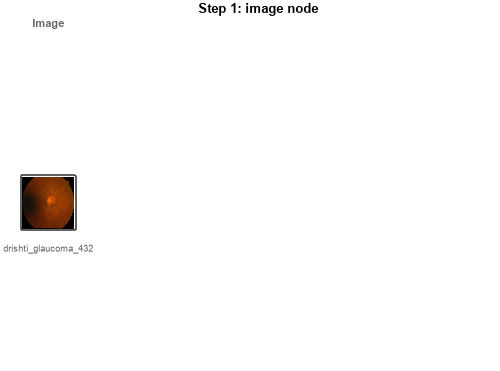

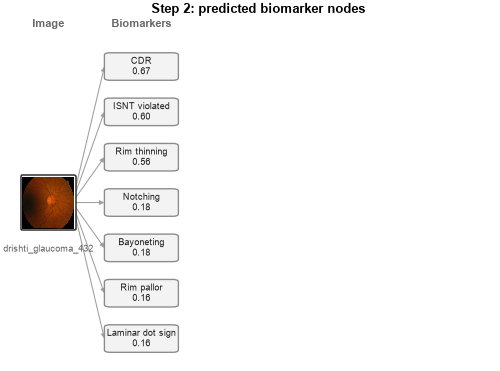

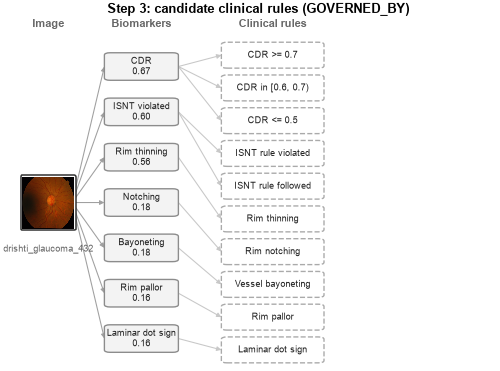

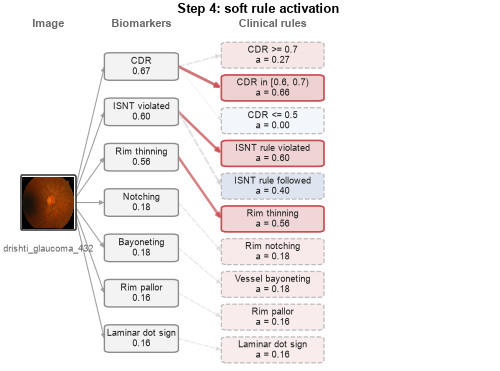

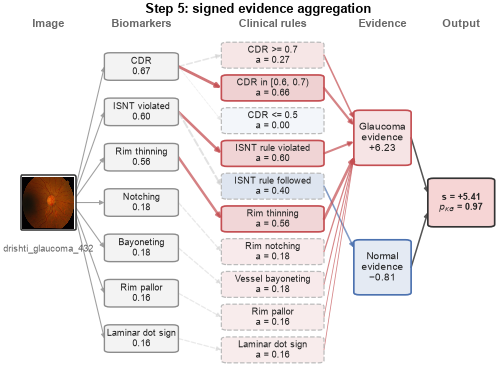

In [86]:
# ═══════════════════════════════════════════════════════════
# Fig 20a–20e: 构建过程（单张图像，每一步一张图，节点位置在各步之间保持不变）
#   a 图像节点  b 预测生物标志物节点  c 候选临床规则（GOVERNED_BY）
#   d 规则激活（线宽/填充 = 激活值）  e 带符号证据汇总 → p_KG
# ═══════════════════════════════════════════════════════════
p_fin = oof_prob("Auto-KG (soft) + Image")
correct = (p_fin >= 0.5).astype(int) == Y_OOF
k_ex = np.where(correct & (Y_OOF == 1))[0][0]           # 示例：一张预测正确的青光眼图像
EX_ID = IDS_OOF[k_ex]
ex_bm = PRED_OOF.iloc[k_ex]
ex_act = rule_activations(ex_bm.to_frame().T.astype(float), CFG, "soft").iloc[0]
ex_img = IMGS[POS[EX_ID]]
ex_p = kg_probability(ex_bm.to_frame().T.astype(float), CFG, "soft")[0]
contrib = {r["id"]: r["evidence"] * CFG.strength_weight[r["strength"]] * ex_act[r["id"]] for r in RULES}
S_G = sum(v for v in contrib.values() if v > 0)
S_N = -sum(v for v in contrib.values() if v < 0)
IMG_R = X_IMG + 0.05                                          # 图像节点右边缘（近似）

def draw_step(step):
    fig, ax = blank()
    column_headers(ax, {1: 1, 2: 2, 3: 3, 4: 3, 5: 5}[step])
    image_node(ax, ex_img, X_IMG, 0.5)
    ax.text(X_IMG, 0.5 - 0.13, EX_ID, ha="center", va="top", fontsize=5.6, color="#666666")
    if step >= 2:                                                # 图像 → 生物标志物
        for b in BM_ORDER:
            link(ax, (IMG_R, 0.5), (X_BM - W_BM / 2, Y_BM[b]), color="#A0A0A0", lw=0.7)
            rect(ax, X_BM, Y_BM[b], W_BM, H_BM, f"{BM_NAMES[b]}\n{float(ex_bm[b]):.2f}", fc="#F3F3F3", ec="#8C8C8C")
    if step >= 3:                                                # 生物标志物 → 规则
        for r in RULES_SORTED:
            a_ = ex_act[r["id"]]
            col = EVID_COLORS[r["evidence"]]
            p, q = (X_BM + W_BM / 2, Y_BM[r["bm"]]), (X_RULE - W_RULE / 2, Y_RULE[r["id"]])
            if step == 3:
                link(ax, p, q, color="#C8C8C8", lw=0.7)
                rect(ax, X_RULE, Y_RULE[r["id"]], W_RULE, H_RULE, r["name"], ec="#AAAAAA", ls="--", fs=5.8)
            else:
                on = a_ >= 0.5
                link(ax, p, q, color=col if on else "#D0D0D0", lw=0.5 + 2.0 * a_, alpha=0.35 + 0.65 * a_,
                     ls="-" if on else "--")
                rect(ax, X_RULE, Y_RULE[r["id"]], W_RULE, H_RULE, f"{r['name']}\na = {a_:.2f}", fs=5.8,
                     fc=mpl.colors.to_rgba(col, 0.06 + 0.30 * a_), ec=col if on else "#BBBBBB",
                     ls="-" if on else "--", lw=1.1 if on else 0.8)
    if step == 5:                                                # 规则 → 证据 → 输出
        for r in RULES_SORTED:
            c = contrib[r["id"]]
            if abs(c) < 0.05:
                continue
            ye = Y_EVI[r["evidence"]] + np.clip((Y_RULE[r["id"]] - Y_EVI[r["evidence"]]) * 0.25, -0.06, 0.06)
            link(ax, (X_RULE + W_RULE / 2, Y_RULE[r["id"]]), (X_EVI - W_EVI / 2, ye),
                 color=EVID_COLORS[r["evidence"]], lw=0.4 + 0.8 * abs(c), alpha=0.7)
        rect(ax, X_EVI, Y_EVI[+1], W_EVI, H_EVI, f"Glaucoma\nevidence\n+{S_G:.2f}",
             fc=mpl.colors.to_rgba(G_COL, 0.15), ec=G_COL, lw=1.1, fs=6.4)
        rect(ax, X_EVI, Y_EVI[-1], W_EVI, H_EVI, f"Normal\nevidence\n−{S_N:.2f}",
             fc=mpl.colors.to_rgba(N_COL, 0.15), ec=N_COL, lw=1.1, fs=6.4)
        for s_ in (+1, -1):
            link(ax, (X_EVI + W_EVI / 2, Y_EVI[s_]), (X_OUT - W_OUT / 2, 0.5 + 0.03 * s_), color="#555555", lw=1.0)
        rect(ax, X_OUT, 0.5, W_OUT, H_OUT, f"s = {S_G - S_N:+.2f}\n$p_{{KG}}$ = {ex_p:.2f}",
             fc="#F6D5D5" if ex_p >= 0.5 else "#D6E2F1", ec="#333333", lw=1.1, fs=6.0, bold=True)
    return fig

STEP_TITLES = {1: "Step 1: image node", 2: "Step 2: predicted biomarker nodes",
               3: "Step 3: candidate clinical rules (GOVERNED_BY)", 4: "Step 4: soft rule activation",
               5: "Step 5: signed evidence aggregation"}
for step, tag in zip(range(1, 6), "abcde"):
    fig = draw_step(step)
    fig.axes[0].set_title(STEP_TITLES[step], pad=16, fontsize=8.5)
    save(fig, f"fig20{tag}_construction_step{step}")

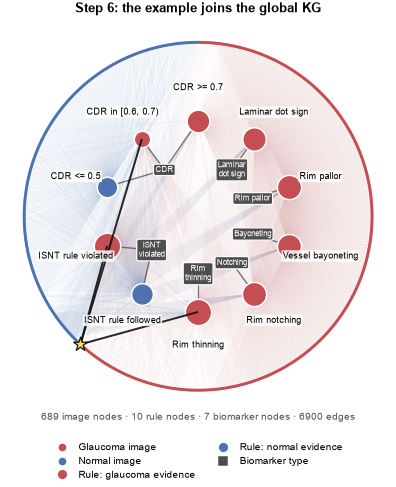

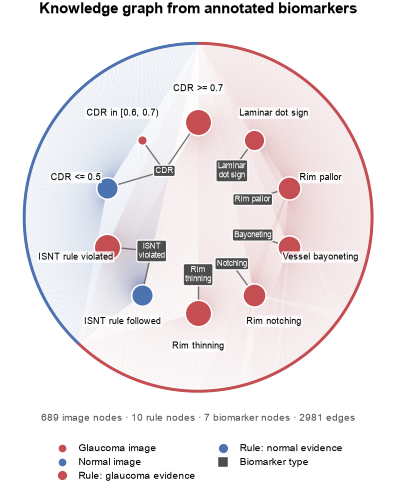

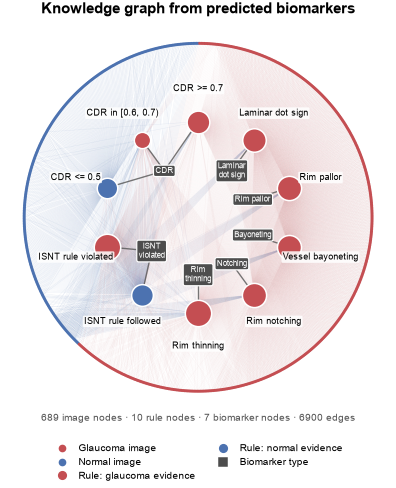

In [87]:
# ═══════════════════════════════════════════════════════════
# Fig 21a / 21b: 最终构建的全局知识图谱（读取 Cell 12 导出的 CSV）
#   内圈：生物标志物类型节点；中圈：临床规则节点（大小 = 支持该规则的图像数）；
#   外圈：每张眼底图一个节点（颜色 = 真实标签）；边：图像 SUPPORTS_RULE 规则（激活 ≥ 0.5）
# Fig 20f: 示例图像在全局图中的位置（构建过程最后一步）
# ═══════════════════════════════════════════════════════════
def load_kg(source):
    n = pd.read_csv(OUT / f"kg_nodes_{source}.csv", low_memory=False)
    e = pd.read_csv(OUT / f"kg_edges_{source}.csv", low_memory=False)
    return n, e

def radial_layout(nodes, edges):
    """返回各节点坐标；规则按所属生物标志物分组排在中圈，生物标志物位于其规则的平均角度"""
    rule_ids = [r["id"] for r in RULES_SORTED]
    ang_rule = dict(zip(rule_ids, np.linspace(0, 2 * np.pi, len(rule_ids), endpoint=False) + np.pi / 2))
    pos = {rid: (0.55 * np.cos(a), 0.55 * np.sin(a)) for rid, a in ang_rule.items()}
    # 生物标志物放在内圈、位于其所属规则的平均角度（规则已按生物标志物分组，连线呈放射状不交叉）
    for b in BM_ORDER:
        angs = [ang_rule[r["id"]] for r in RULES if r["bm"] == b]
        a = np.angle(np.mean(np.exp(1j * np.array(angs))))
        pos[f"bm_{b}"] = (0.33 * np.cos(a), 0.33 * np.sin(a))
    img = nodes[nodes.label == "FundusImage"].copy()
    sup = edges[(edges.rel == "SUPPORTS_RULE") & (edges.weight >= 0.5)]
    # 每张图像放在其激活规则的平均角度附近，使连线成束；同时按标签分到两个半圆
    mean_ang = {}
    for src, g in sup.groupby("src"):
        mean_ang[src] = np.angle(np.mean(np.exp(1j * np.array([ang_rule[d] for d in g.dst]))))
    img["ang"] = img["id"].map(mean_ang).fillna(0.0)
    img = img.sort_values(["bin_label", "ang"])
    img_ang = np.linspace(0, 2 * np.pi, len(img), endpoint=False) + np.pi / 2
    for iid, a in zip(img["id"], img_ang):
        pos[iid] = (np.cos(a), np.sin(a))
    return pos, img, sup

def draw_global_kg(source, title, highlight=None):
    nodes, edges = load_kg(source)
    pos, img, sup = radial_layout(nodes, edges)
    lab = dict(zip(img["id"], img["bin_label"]))
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    for lv in [0, 1]:                                           # 图像 → 规则
        seg = [(pos[s], pos[d]) for s, d in zip(sup.src, sup.dst) if lab.get(s) == lv and s in pos]
        ax.add_collection(LineCollection(seg, colors=CLS_COLORS[lv], linewidths=0.3,
                                         alpha=float(np.clip(60 / max(len(seg), 1), 0.04, 0.25)), zorder=1))
    gov = edges[edges.rel == "GOVERNED_BY"]                     # 生物标志物 → 规则
    ax.add_collection(LineCollection([(pos[s], pos[d]) for s, d in zip(gov.src, gov.dst)],
                                     colors="#555555", linewidths=0.9, alpha=0.8, zorder=2))
    xy = np.array([pos[i] for i in img["id"]])
    ax.scatter(xy[:, 0], xy[:, 1], s=4, c=[CLS_COLORS[int(v)] for v in img["bin_label"]], lw=0, zorder=3)
    support = sup.groupby("dst").size()
    for r in RULES_SORTED:
        x_, y_ = pos[r["id"]]
        ax.scatter(x_, y_, s=40 + 260 * support.get(r["id"], 0) / max(support.max(), 1),
                   color=EVID_COLORS[r["evidence"]], ec="white", lw=1.0, zorder=4)
        ang = np.arctan2(y_, x_)
        ax.text(0.74 * np.cos(ang), 0.74 * np.sin(ang), r["name"], fontsize=5.6, ha="center", va="center", zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for b in BM_ORDER:
        x_, y_ = pos[f"bm_{b}"]
        ax.text(x_, y_, BM_NAMES[b].replace(" ", "\n", 1) if len(BM_NAMES[b]) > 10 else BM_NAMES[b],
                fontsize=5.0, ha="center", va="center", color="white", zorder=6,
                bbox=dict(boxstyle="round,pad=0.25", fc="#4D4D4D", ec="white", lw=0.8))
    if highlight is not None and highlight in pos:              # 高亮示例图像及其子图
        hs = sup[sup.src == highlight]
        ax.add_collection(LineCollection([(pos[s], pos[d]) for s, d in zip(hs.src, hs.dst)],
                                         colors="#111111", linewidths=1.3, alpha=0.9, zorder=5))
        ax.scatter(*pos[highlight], s=90, marker="*", color="#F0E442", ec="#111111", lw=0.8, zorder=7)
    n_img, n_e = len(img), len(edges)
    ax.text(0, -1.17, f"{n_img} image nodes · {len(RULES)} rule nodes · {len(BM_ORDER)} biomarker nodes · {n_e} edges",
            ha="center", fontsize=6.5, color="#555555")
    handles = [Line2D([], [], marker="o", ls="", color=CLS_COLORS[1], ms=4, label="Glaucoma image"),
               Line2D([], [], marker="o", ls="", color=CLS_COLORS[0], ms=4, label="Normal image"),
               Line2D([], [], marker="o", ls="", color=G_COL, ms=7, mec="white", label="Rule: glaucoma evidence"),
               Line2D([], [], marker="o", ls="", color=N_COL, ms=7, mec="white", label="Rule: normal evidence"),
               Line2D([], [], marker="s", ls="", color="#4D4D4D", ms=5, label="Biomarker type")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2, fontsize=6.3)
    ax.set(xlim=(-1.12, 1.12), ylim=(-1.12, 1.12), title=title)
    ax.set_aspect("equal"); ax.axis("off")
    return fig

fig = draw_global_kg("auto", "Step 6: the example joins the global KG", highlight=f"img_{EX_ID}")
fig.axes[0].title.set_fontsize(8.5)
save(fig,
     "fig20f_construction_step6_global")
save(draw_global_kg("oracle", "Knowledge graph from annotated biomarkers"), "fig21a_global_kg_oracle")
save(draw_global_kg("auto", "Knowledge graph from predicted biomarkers"), "fig21b_global_kg_auto")

,Oracle KG,Auto KG
FundusImage nodes,689,689
ClinicalRule nodes,10,10
BiomarkerType nodes,7,7
GOVERNED_BY edges,10,10
SUPPORTS_RULE edges (a ≥ 0.5),2971,3104
SUPPORTS_RULE edges (all a > 0),2971,6890


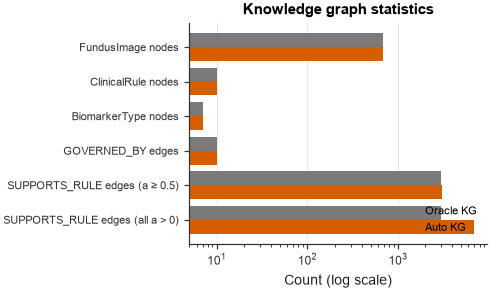

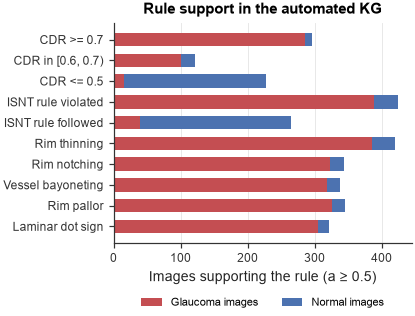

In [88]:
# ═══════════════════════════════════════════════════════════
# Fig 21c: 知识图谱统计（节点类型与边类型数量，标注版 vs 自动版）
# Fig 21d: 每条规则支持的图像数（按真实标签分色，自动版）
# ═══════════════════════════════════════════════════════════
stats = {}
for src in ["oracle", "auto"]:
    n, e = load_kg(src)
    sup = e[(e.rel == "SUPPORTS_RULE") & (e.weight >= 0.5)]
    stats[src] = {**{f"{k} nodes": v for k, v in n.label.value_counts().items()},
                  "GOVERNED_BY edges": int((e.rel == "GOVERNED_BY").sum()),
                  "SUPPORTS_RULE edges (a ≥ 0.5)": len(sup),
                  "SUPPORTS_RULE edges (all a > 0)": int((e.rel == "SUPPORTS_RULE").sum())}
kg_stats = pd.DataFrame(stats).fillna(0).astype(int)
kg_stats.columns = ["Oracle KG", "Auto KG"]
to_booktabs(kg_stats, "table_kg_statistics", "Statistics of the constructed knowledge graphs.", "tab:kgstats",
            float_fmt="{:.0f}")
display(kg_stats)

fig, ax = plt.subplots(figsize=SINGLE)
yy = np.arange(len(kg_stats))
ax.barh(yy - 0.2, kg_stats["Oracle KG"], 0.4, color="#7A7A7A", label="Oracle KG")
ax.barh(yy + 0.2, kg_stats["Auto KG"], 0.4, color="#D55E00", label="Auto KG")
ax.set_yticks(yy); ax.set_yticklabels(kg_stats.index, fontsize=7)
ax.set_xscale("log")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="Count (log scale)", title="Knowledge graph statistics")
ax.legend(loc="lower right")
save(fig, "fig21c_kg_statistics")

n, e = load_kg("auto")
lab = dict(zip(n.loc[n.label == "FundusImage", "id"], n.loc[n.label == "FundusImage", "bin_label"]))
sup = e[(e.rel == "SUPPORTS_RULE") & (e.weight >= 0.5)].copy()
sup["y"] = sup.src.map(lab)
cnt = sup.groupby(["dst", "y"]).size().unstack(fill_value=0).reindex([r["id"] for r in RULES_SORTED], fill_value=0)
fig, ax = plt.subplots(figsize=SINGLE)
names = [RULE_NAMES[i] for i in cnt.index]
ax.barh(names, cnt.get(1, 0), color=CLS_COLORS[1], label="Glaucoma images", height=0.65)
ax.barh(names, cnt.get(0, 0), left=cnt.get(1, 0), color=CLS_COLORS[0], label="Normal images", height=0.65)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="Images supporting the rule (a ≥ 0.5)", title="Rule support in the automated KG")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
save(fig, "fig21d_rule_support")

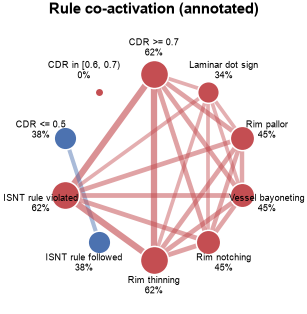

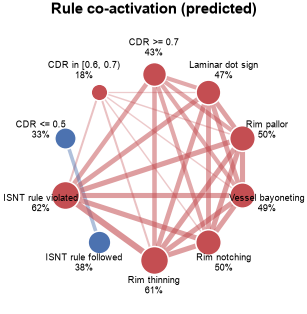

In [89]:
# ═══════════════════════════════════════════════════════════
# Fig 22a / 22b: 规则共激活网络（标注 / 预测）
#   节点 = 规则（大小 = 激活频率），边 = 两条规则同时激活的图像比例（只画 ≥ 5% 的边）
# ═══════════════════════════════════════════════════════════
def coactivation_graph(bm_, mode, title):
    A = rule_activations(bm_, CFG, mode)[[r["id"] for r in RULES_SORTED]].values >= 0.5
    freq = A.mean(0)
    co = (A[:, :, None] & A[:, None, :]).mean(0)
    ang = np.linspace(0, 2 * np.pi, len(RULES_SORTED), endpoint=False) + np.pi / 2
    xy = np.c_[np.cos(ang), np.sin(ang)]
    fig, ax = plt.subplots(figsize=(3.4, 3.4))
    for i in range(len(RULES_SORTED)):
        for j in range(i + 1, len(RULES_SORTED)):
            if co[i, j] >= 0.05:
                same = RULES_SORTED[i]["evidence"] == RULES_SORTED[j]["evidence"]
                col = EVID_COLORS[RULES_SORTED[i]["evidence"]] if same else "#7F7F7F"
                ax.plot(*xy[[i, j]].T, color=col, lw=0.4 + 6 * co[i, j], alpha=0.25 + 0.6 * co[i, j],
                        solid_capstyle="round", zorder=1)
    for i, r in enumerate(RULES_SORTED):
        ax.scatter(*xy[i], s=30 + 500 * freq[i], color=EVID_COLORS[r["evidence"]], ec="white", lw=1.0, zorder=3)
        ax.text(*(xy[i] * 1.28), f"{r['name']}\n{freq[i]:.0%}", ha="center", va="center", fontsize=5.8)
    ax.set(xlim=(-1.55, 1.55), ylim=(-1.55, 1.55), title=title)
    ax.set_aspect("equal"); ax.axis("off")
    return fig

save(coactivation_graph(ANN_OOF, "hard", "Rule co-activation (annotated)"), "fig22a_coactivation_annotated")
save(coactivation_graph(PRED_OOF, "soft", "Rule co-activation (predicted)"), "fig22b_coactivation_predicted")